In [1]:
# !pip install git+https://github.com/facebookresearch/segment-anything.git
# !pip install opencv-python pycocotools matplotlib onnxruntime onnx
using_colab = True

In [2]:
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/sam2.git'

    !mkdir -p images
    !wget -P images https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/cars.jpg

    !mkdir -p ../checkpoints/
    !wget -P ../checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt

PyTorch version: 2.7.1
Torchvision version: 0.22.1
CUDA is available: False
  Cloning https://github.com/facebookresearch/sam2.git to /private/var/folders/pc/j9wt0c0x3lz2jxp97f569thw0000gn/T/pip-req-build-vz0ncebf
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /private/var/folders/pc/j9wt0c0x3lz2jxp97f569thw0000gn/T/pip-req-build-vz0ncebf
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached tqdm-4.67.1-py3-none-any.whl.metadata (57 kB)
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
Using cached tqdm-4.67.1-py3-none-any.whl (78 kB)
  Created wheel for SAM-2: filename=sam_2-1.0-py3-none-any.whl size=181434 sha256=59fc82752abaa3599d69f2097ba6c4f127f4199c9906b15457d61e3b803e9a8b
  Stored in directory: /

In [5]:
import os
# if using Apple MPS, fall back to CPU for unsupported ops
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
# select the device for computation
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"using device: {device}")

if device.type == "cuda":
    # use bfloat16 for the entire notebook
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    # turn on tfloat32 for Ampere GPUs (https://pytorch.org/docs/stable/notes/cuda.html#tensorfloat-32-tf32-on-ampere-devices)
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
elif device.type == "mps":
    print(
        "\nSupport for MPS devices is preliminary. SAM 2 is trained with CUDA and might "
        "give numerically different outputs and sometimes degraded performance on MPS. "
        "See e.g. https://github.com/pytorch/pytorch/issues/84936 for a discussion."
    )

using device: mps

Support for MPS devices is preliminary. SAM 2 is trained with CUDA and might give numerically different outputs and sometimes degraded performance on MPS. See e.g. https://github.com/pytorch/pytorch/issues/84936 for a discussion.


In [5]:
np.random.seed(3)

def show_anns(anns, borders=True):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)

    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:, :, 3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.5]])
        img[m] = color_mask 
        if borders:
            import cv2
            contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE) 
            # Try to smooth contours
            contours = [cv2.approxPolyDP(contour, epsilon=0.01, closed=True) for contour in contours]
            cv2.drawContours(img, contours, -1, (0, 0, 1, 0.4), thickness=1) 

    ax.imshow(img)

Example image

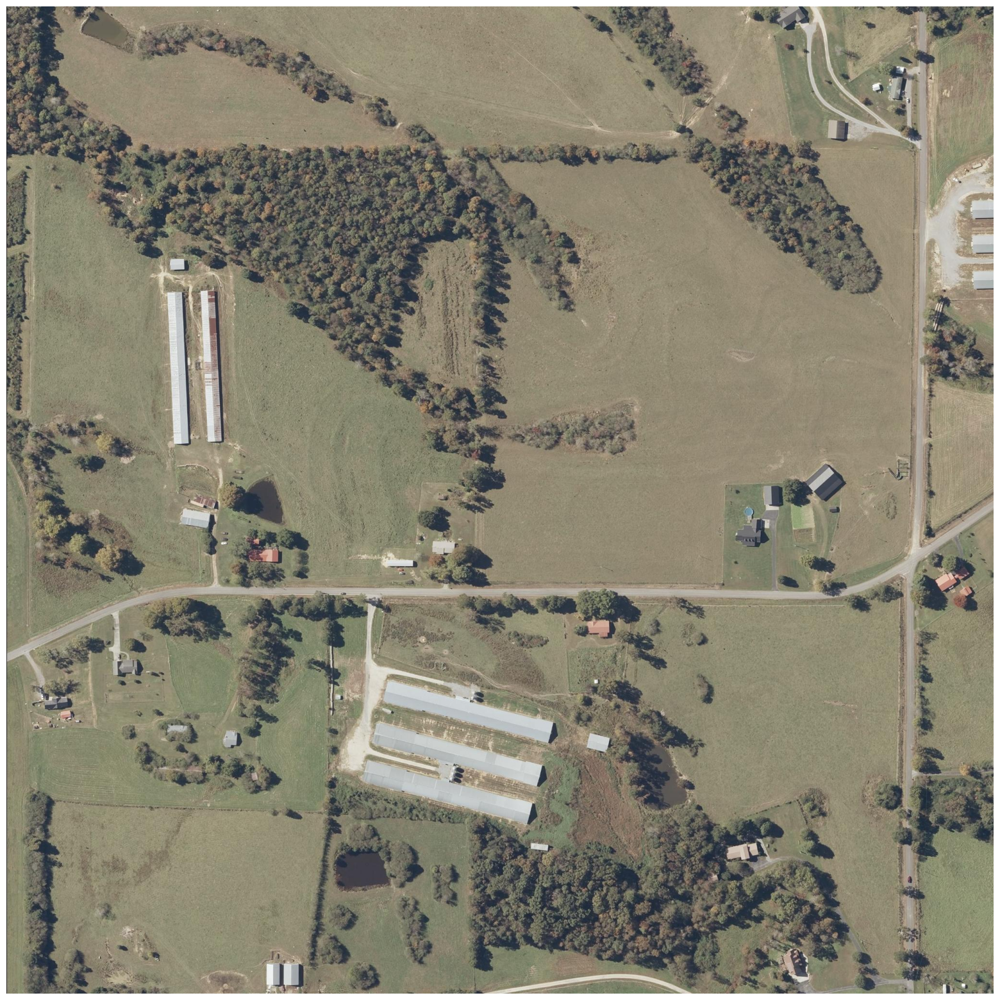

In [6]:
image = Image.open('task/samples/images/tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c.png')
image = np.array(image.convert("RGB"))
plt.figure(figsize=(20, 20))
plt.imshow(image)
plt.axis('off')
plt.show()

## Automatic mask generation
To run automatic mask generation, provide a version of SAM 2 to the SAM2AutomaticMaskGenerator class. Set the path below to the SAM 2 checkpoint.

In [3]:
from sam2.build_sam import build_sam2
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

sam2_checkpoint = "../checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

sam2 = build_sam2(model_cfg, sam2_checkpoint, device=device, apply_postprocessing=False)

mask_generator = SAM2AutomaticMaskGenerator(sam2)

To generate masks, just run generate on an image.

In [8]:
import time

start_time = time.time()
masks = mask_generator.generate(image)
end_time = time.time()
elapsed = end_time - start_time

print(f"Mask generation took {elapsed:.2f} seconds")


Mask generation took 575.98 seconds


Mask generation returns a list over masks, where each mask is a dictionary containing various data about the mask. These keys are:

segmentation : the mask
area : the area of the mask in pixels
bbox : the boundary box of the mask in XYWH format
predicted_iou : the model's own prediction for the quality of the mask
point_coords : the sampled input point that generated this mask
stability_score : an additional measure of mask quality
crop_box : the crop of the image used to generate this mask in XYWH format

In [18]:
print(len(masks))
print(masks[0].keys())

80
dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


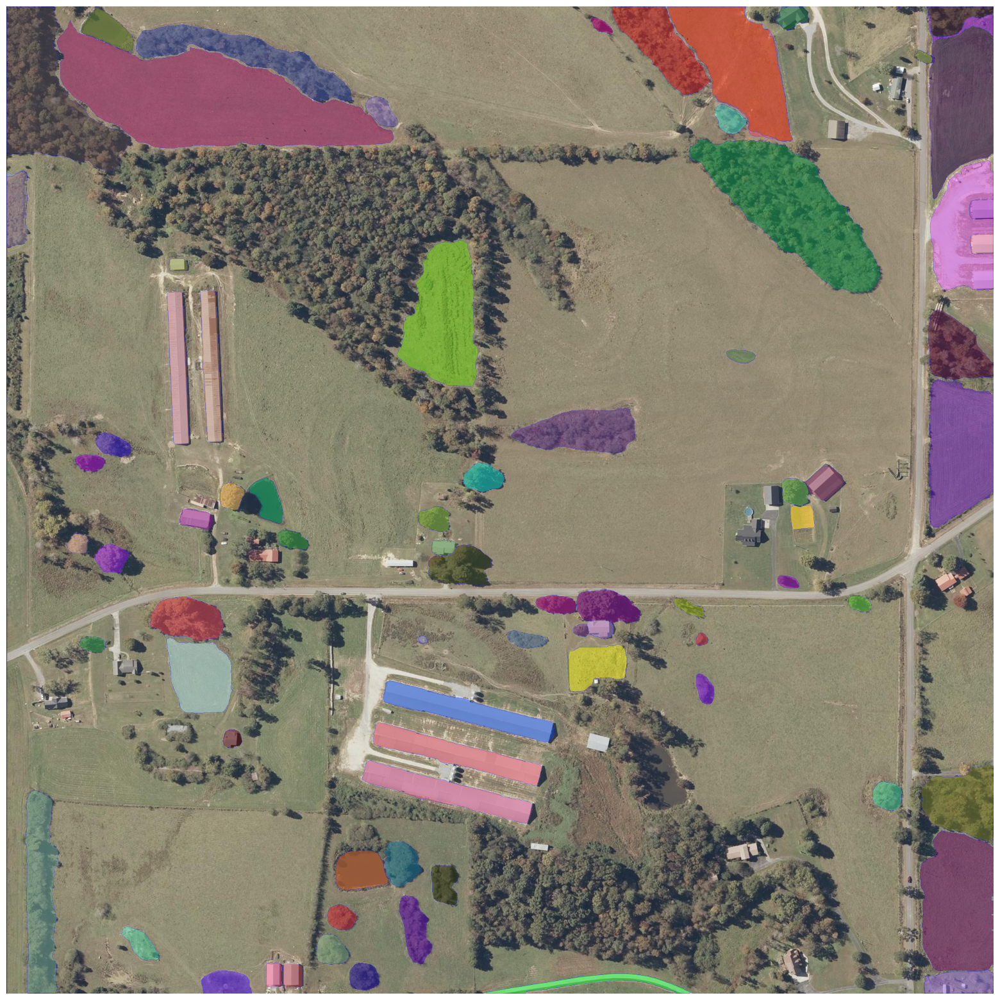

In [9]:
plt.figure(figsize=(20, 20))
plt.imshow(image)
show_anns(masks)
plt.axis('off')
plt.show() 

Automatic mask generation options
There are several tunable parameters in automatic mask generation that control how densely points are sampled and what the thresholds are for removing low quality or duplicate masks. Additionally, generation can be automatically run on crops of the image to get improved performance on smaller objects, and post-processing can remove stray pixels and holes. Here is an example configuration that samples more masks:

using device: mps

Support for MPS devices is preliminary. SAM 2 is trained with CUDA and might give numerically different outputs and sometimes degraded performance on MPS.
Found 108 images.
Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_0_sam2.png


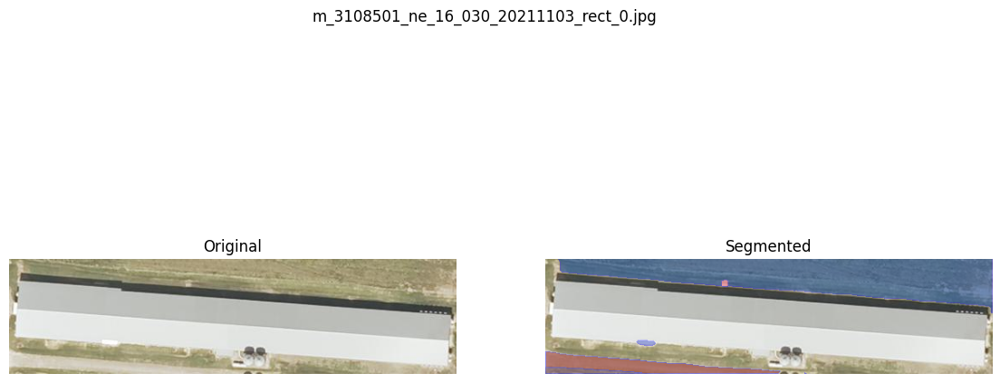

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_1_sam2.png


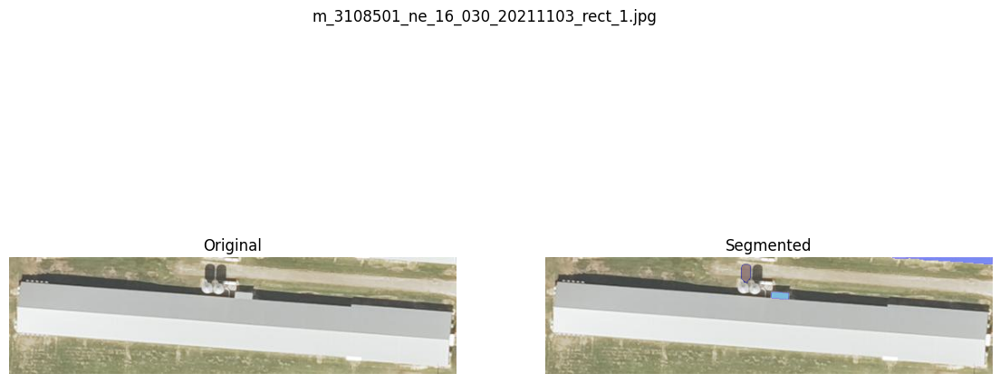

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_10_sam2.png


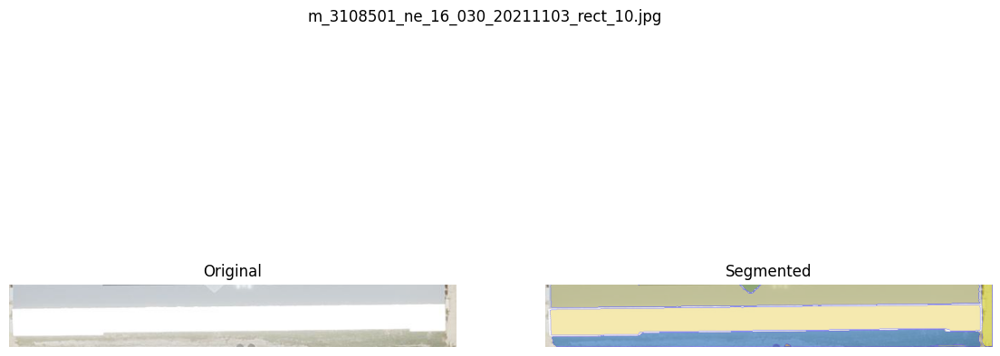

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_11_sam2.png


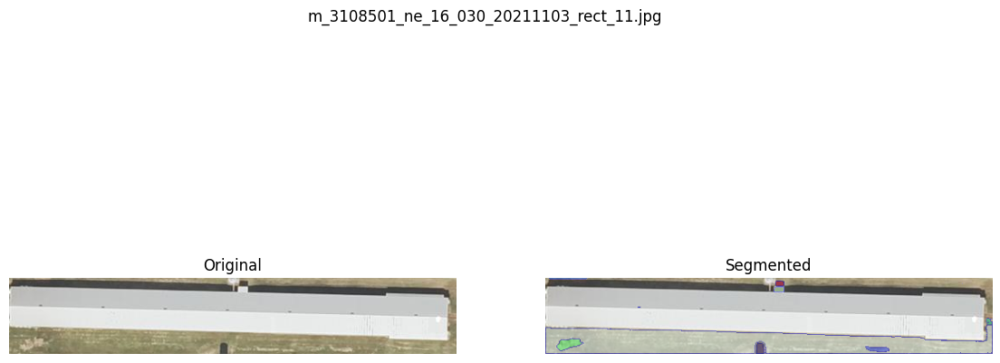

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_12_sam2.png


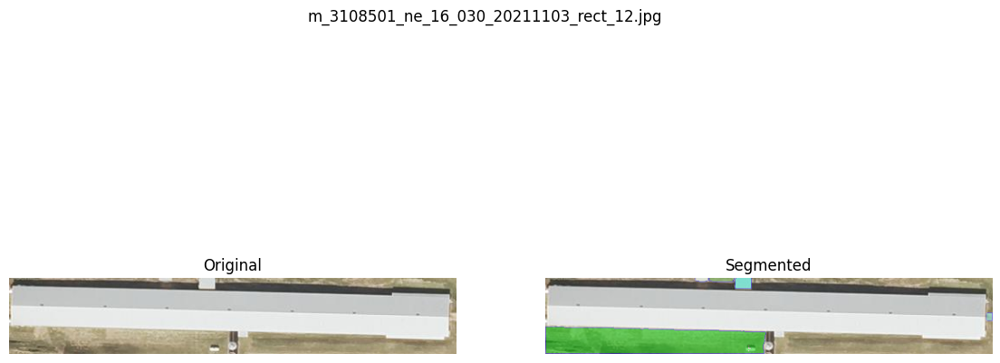

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_13_sam2.png


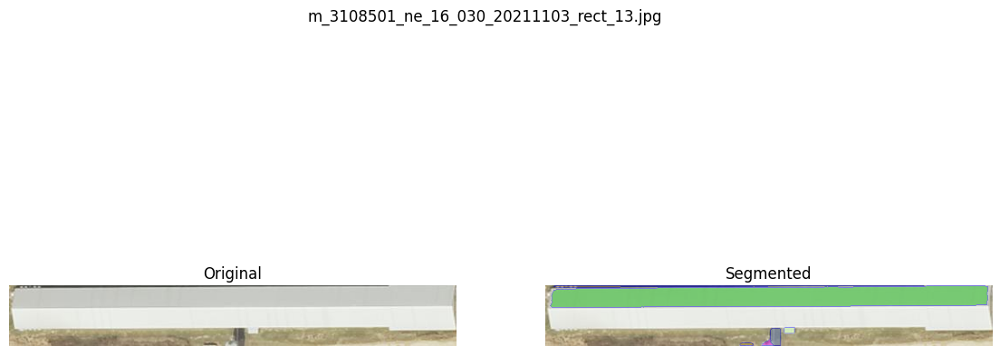

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_14_sam2.png


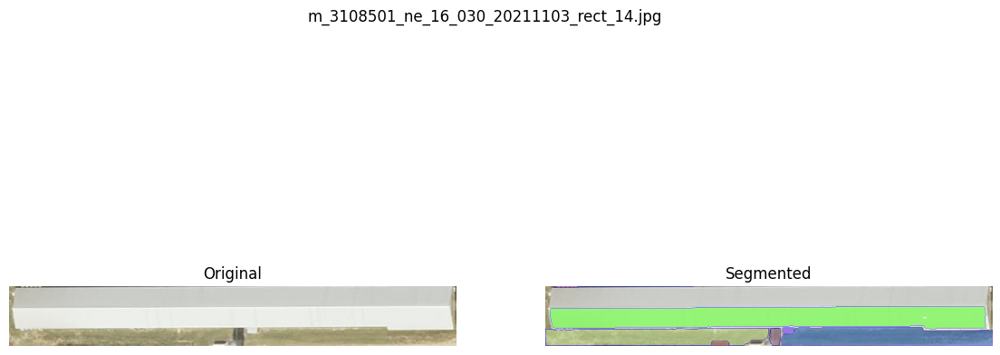

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_15_sam2.png


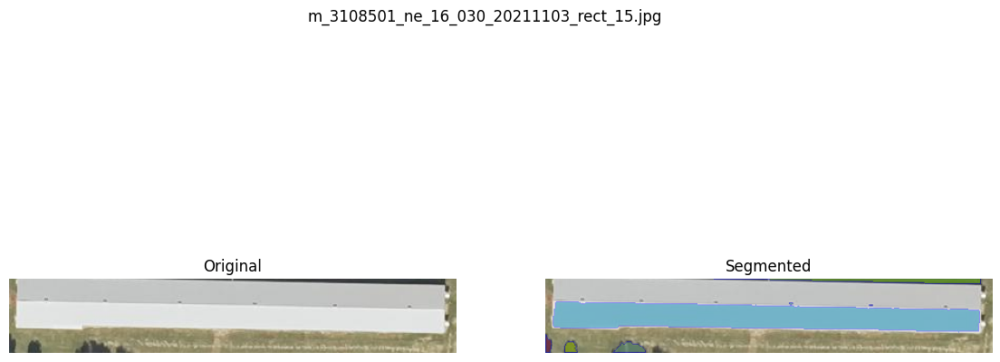

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_16_sam2.png


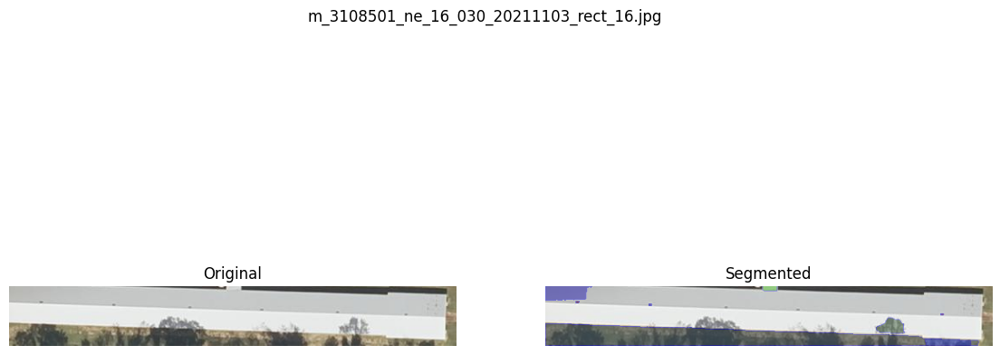

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_17_sam2.png


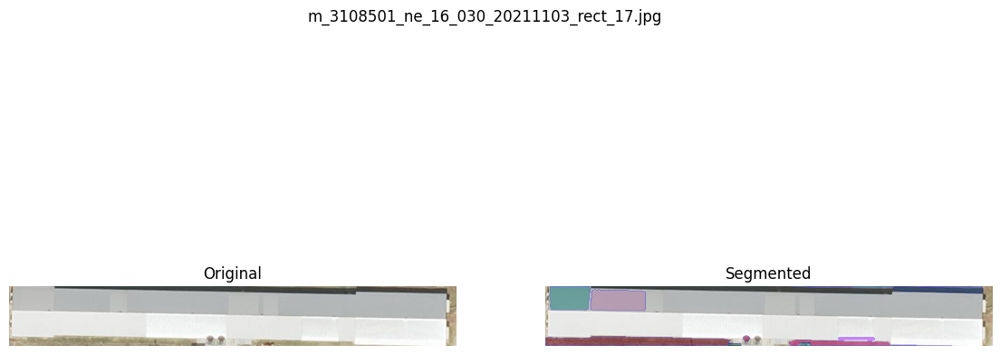

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_18_sam2.png


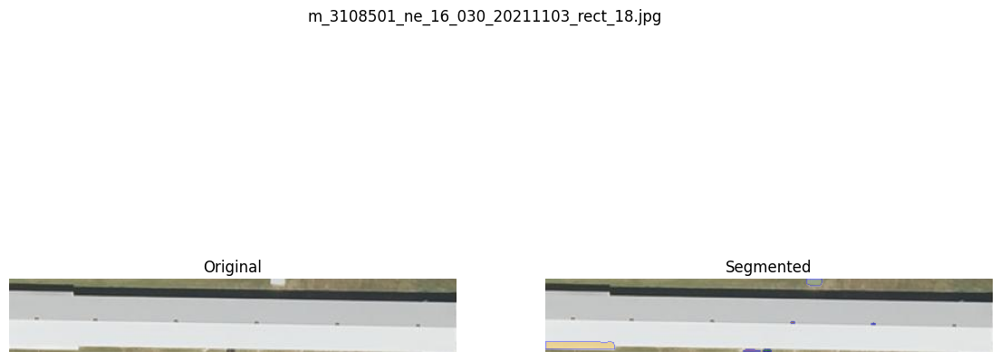

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_19_sam2.png


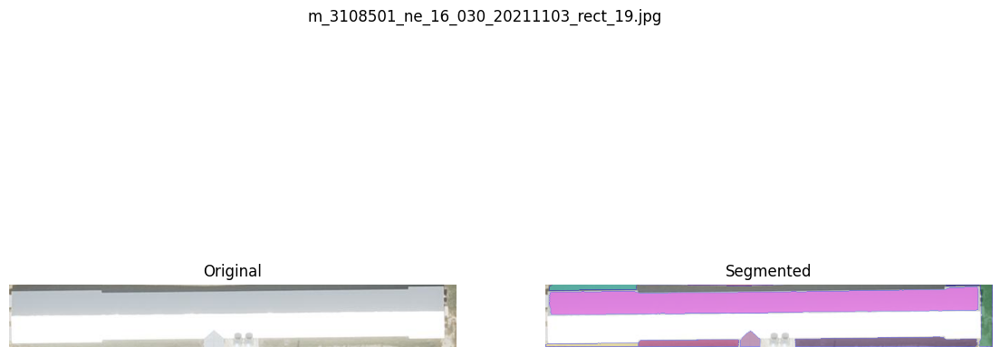

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_2_sam2.png


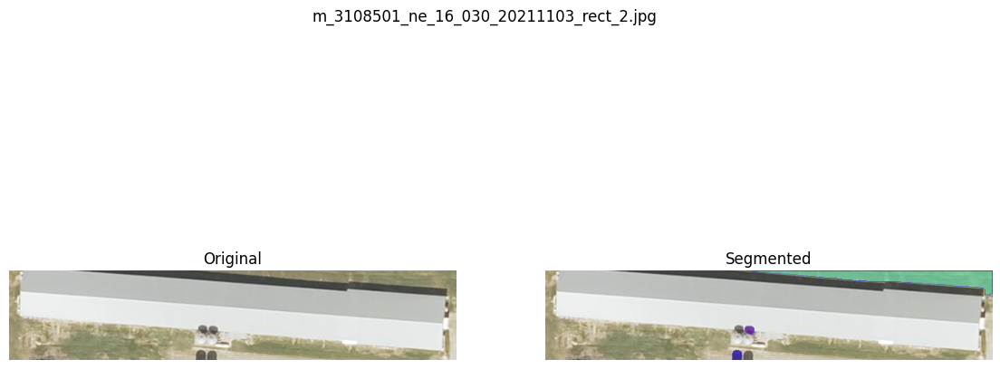

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_20_sam2.png


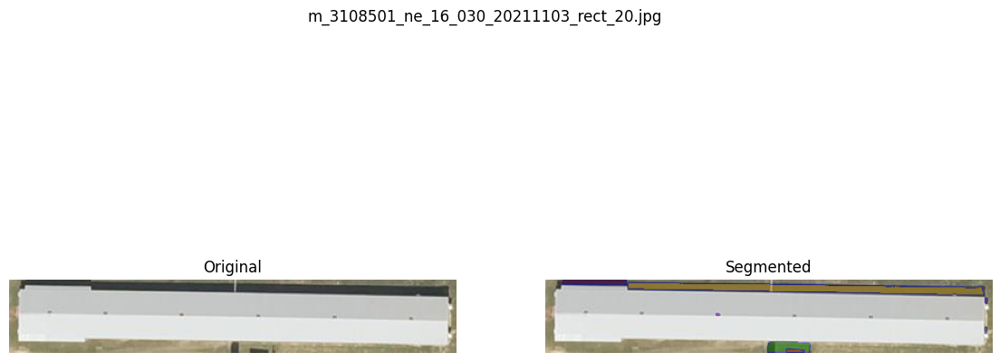

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_21_sam2.png


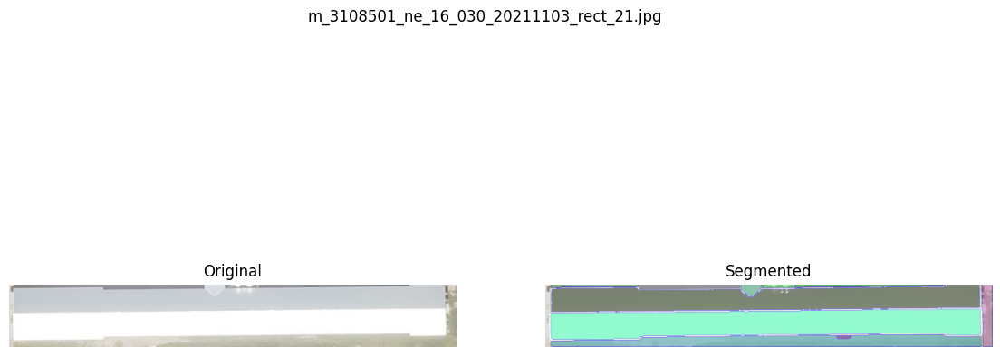

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_3_sam2.png


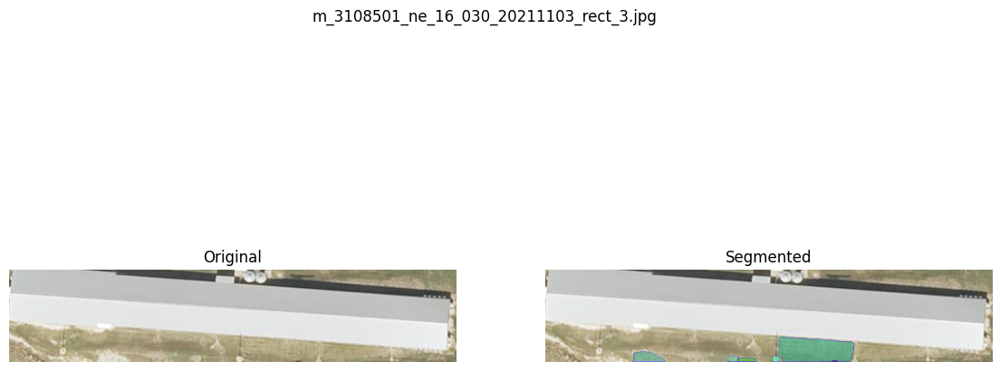

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_4_sam2.png


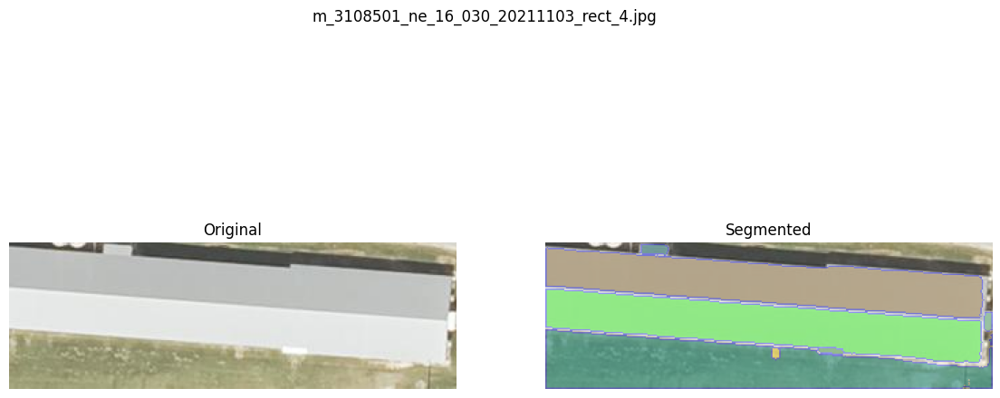

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_5_sam2.png


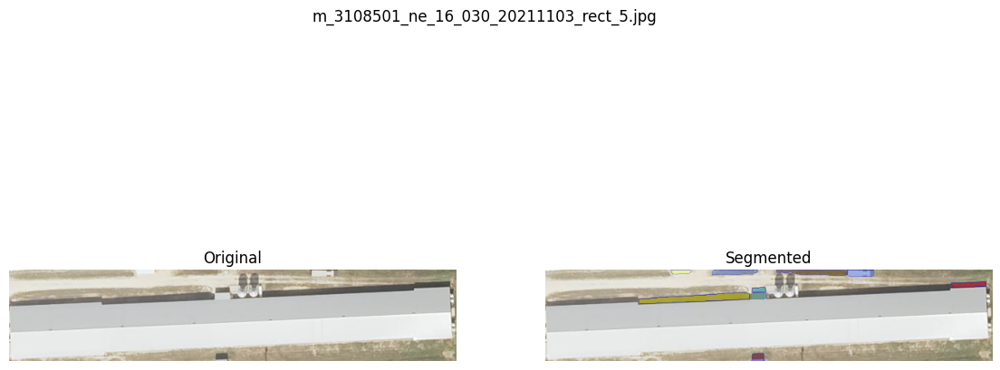

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_6_sam2.png


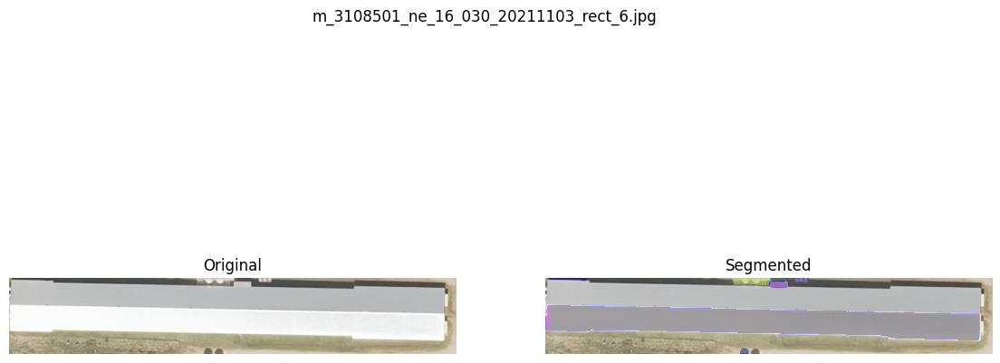

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_7_sam2.png


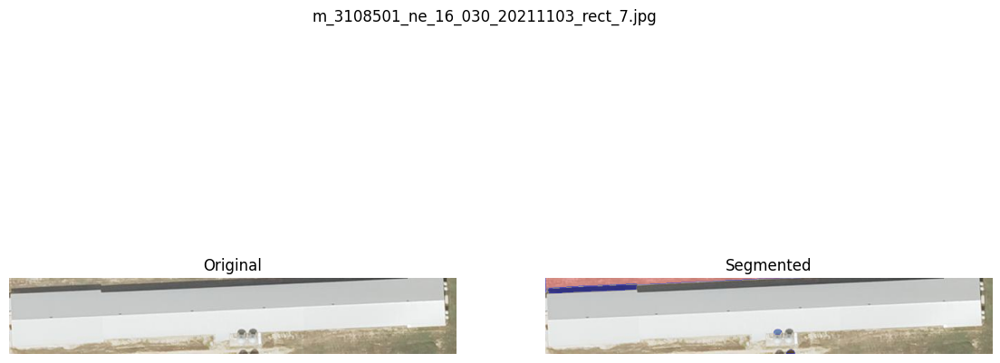

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_8_sam2.png


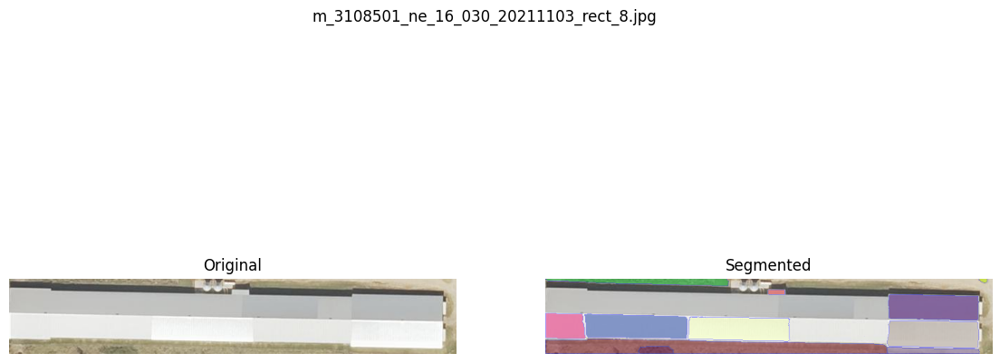

Saved: sam2_output_vis/m_3108501_ne_16_030_20211103_rect_9_sam2.png


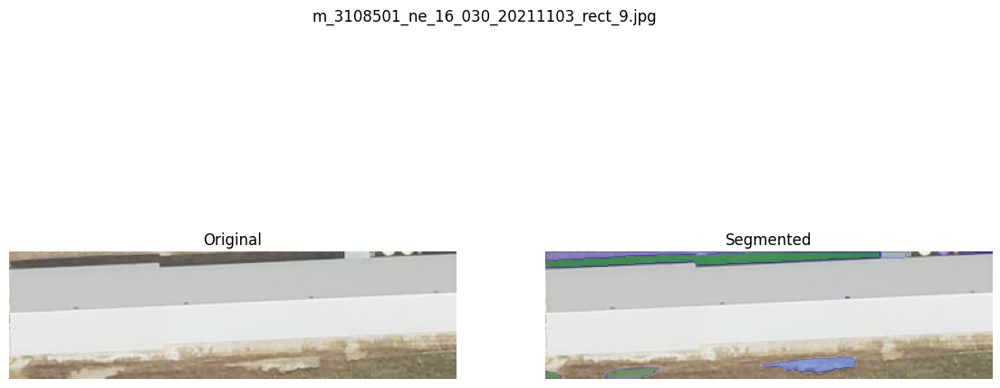

Saved: sam2_output_vis/m_3108501_nw_16_030_20211103_rect_0_sam2.png


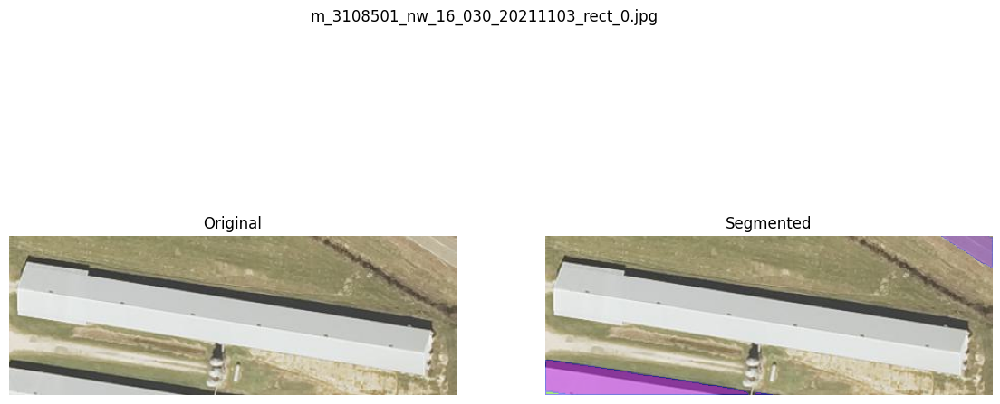

Saved: sam2_output_vis/m_3108501_nw_16_030_20211103_rect_1_sam2.png


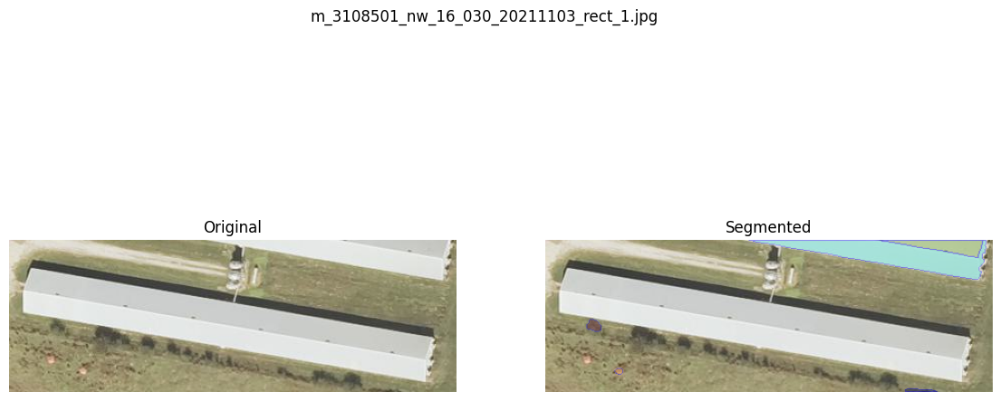

Saved: sam2_output_vis/m_3108501_nw_16_030_20211103_rect_2_sam2.png


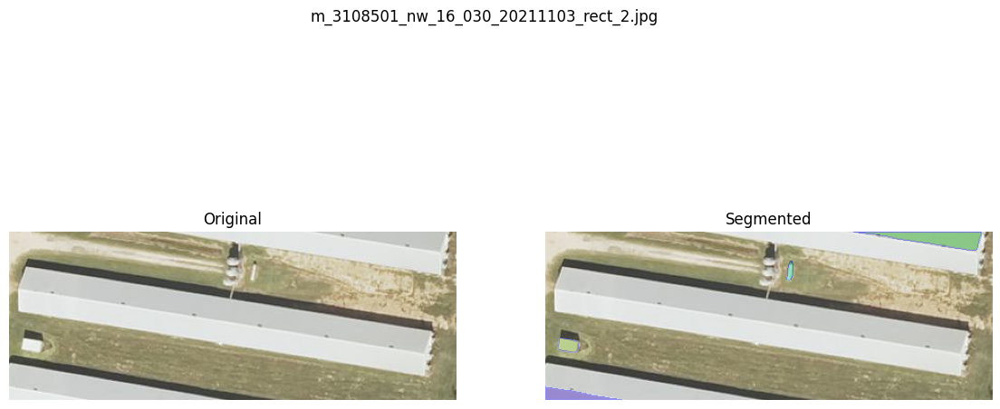

Saved: sam2_output_vis/m_3108501_nw_16_030_20211103_rect_3_sam2.png


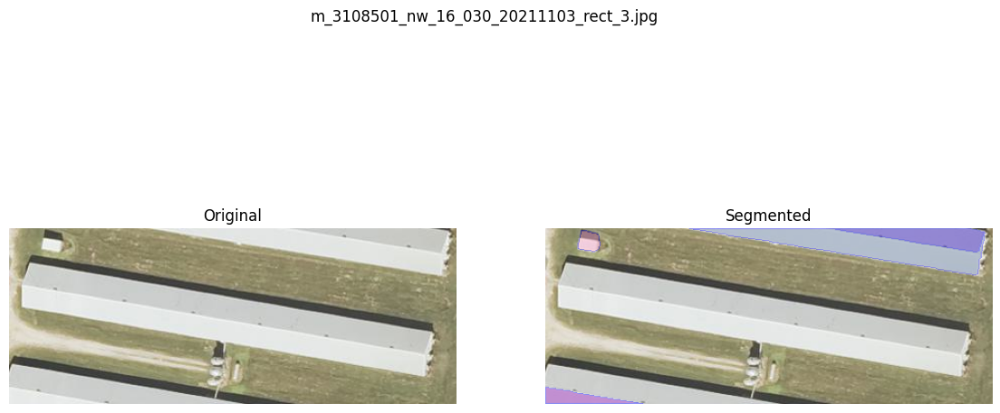

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_0_sam2.png


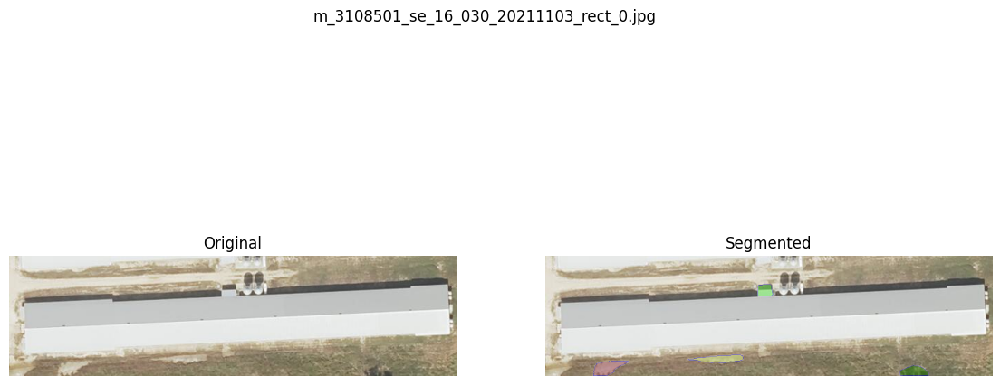

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_1_sam2.png


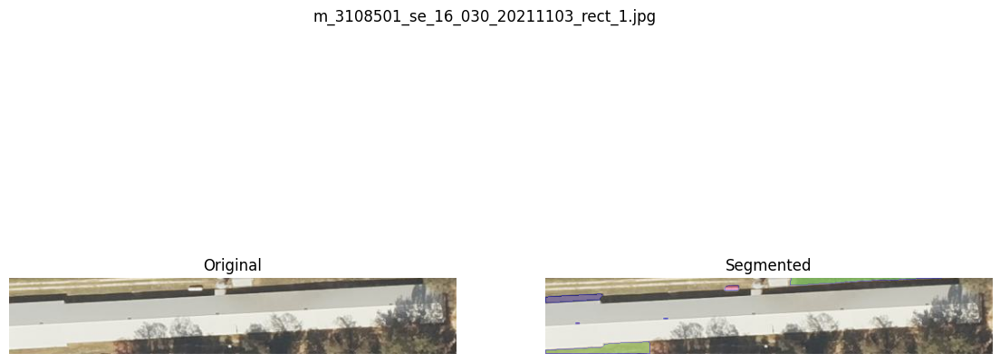

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_10_sam2.png


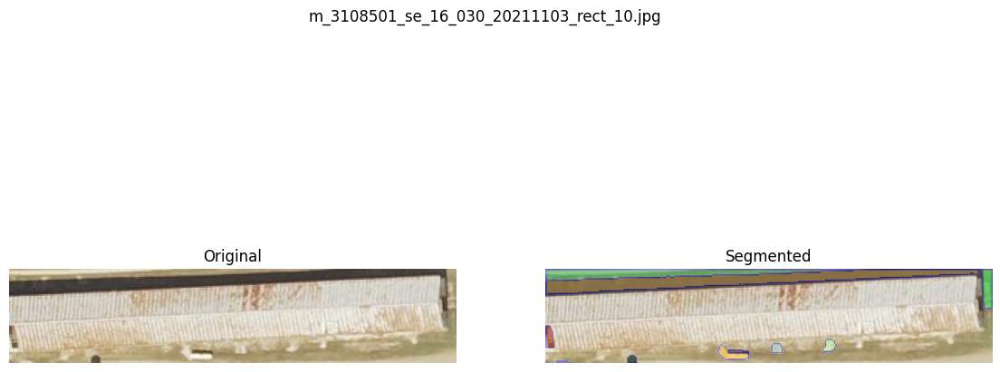

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_11_sam2.png


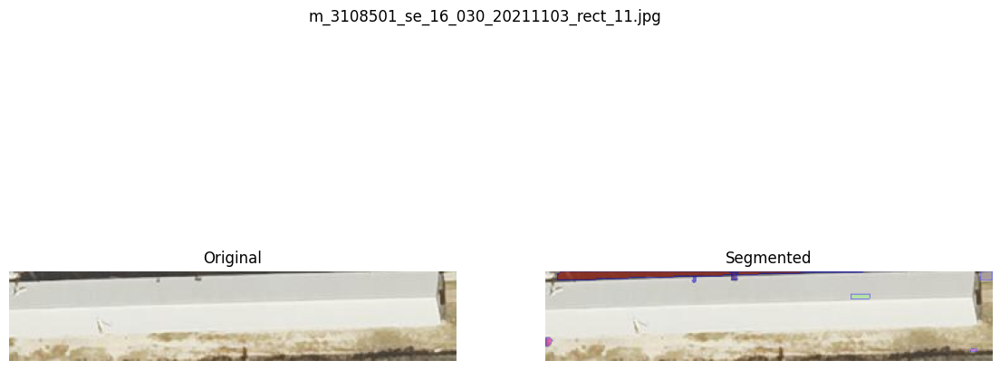

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_12_sam2.png


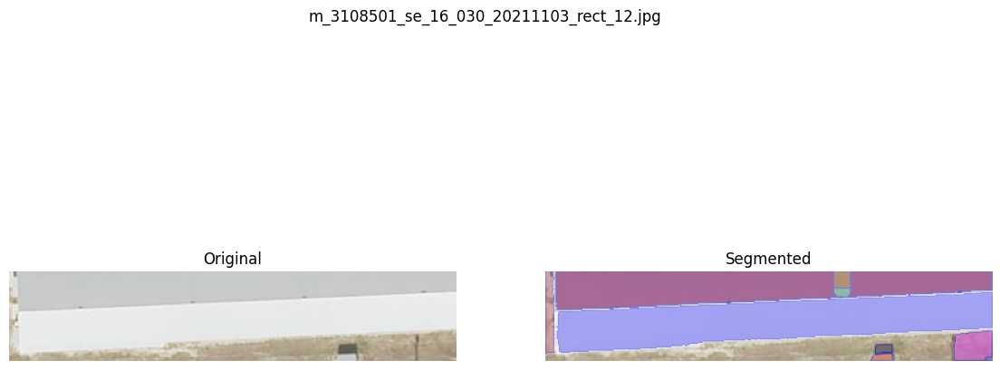

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_13_sam2.png


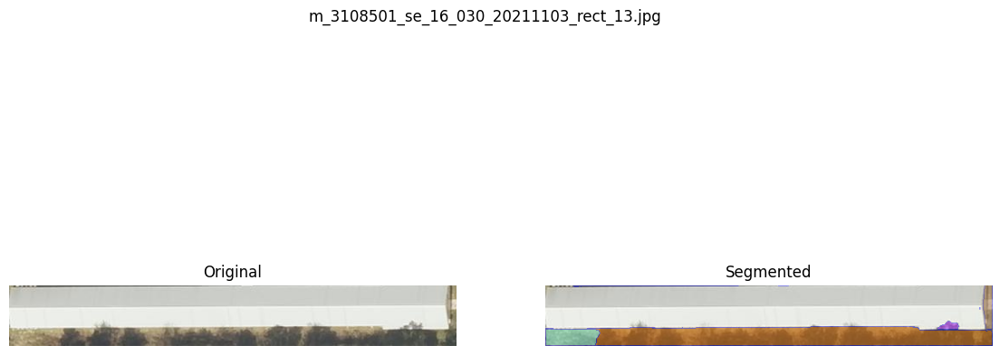

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_14_sam2.png


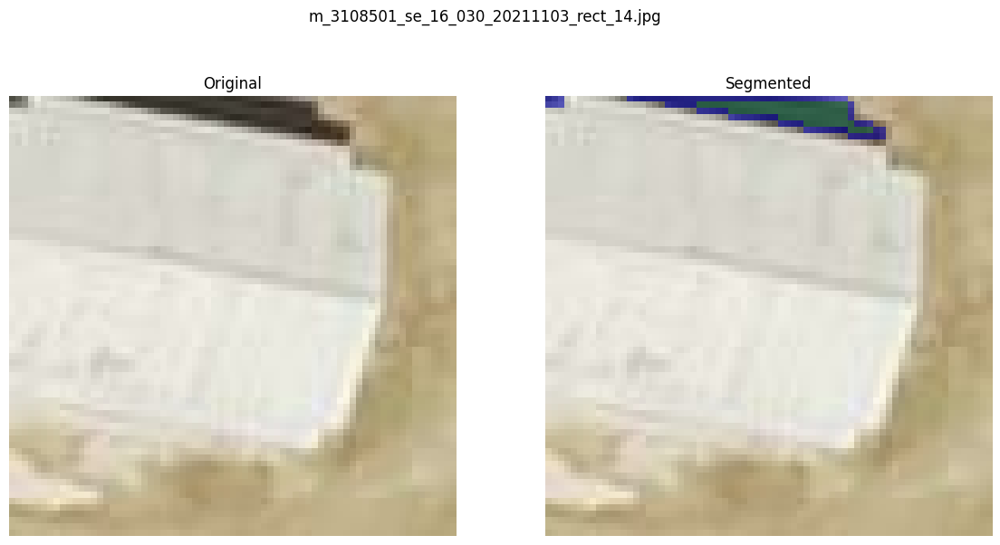

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_2_sam2.png


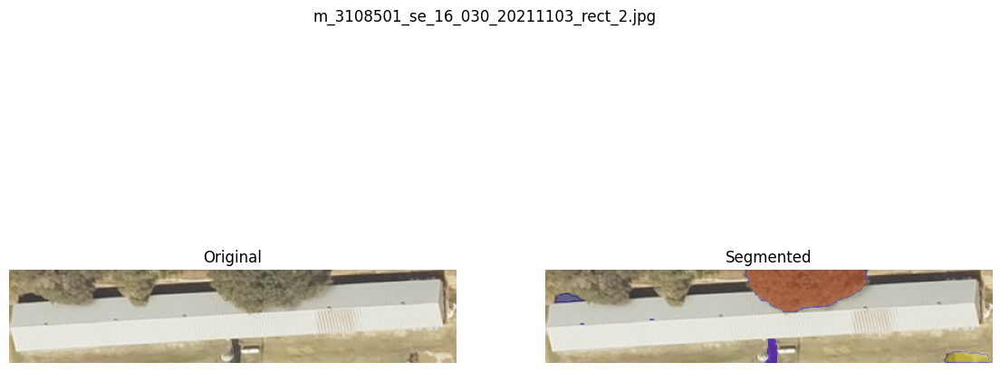

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_3_sam2.png


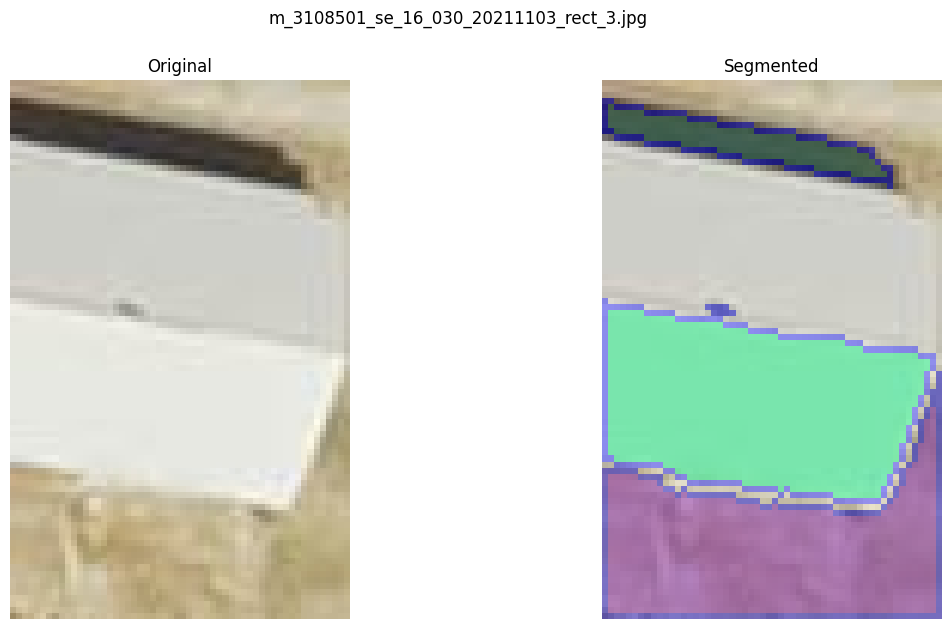

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_4_sam2.png


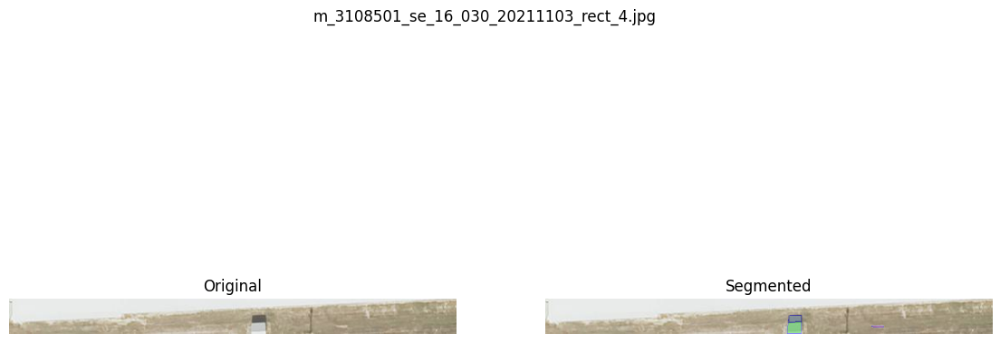

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_5_sam2.png


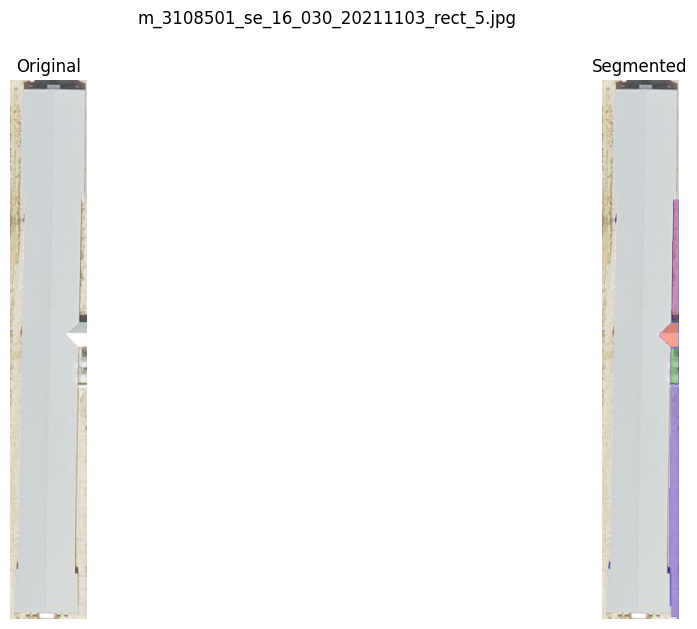

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_6_sam2.png


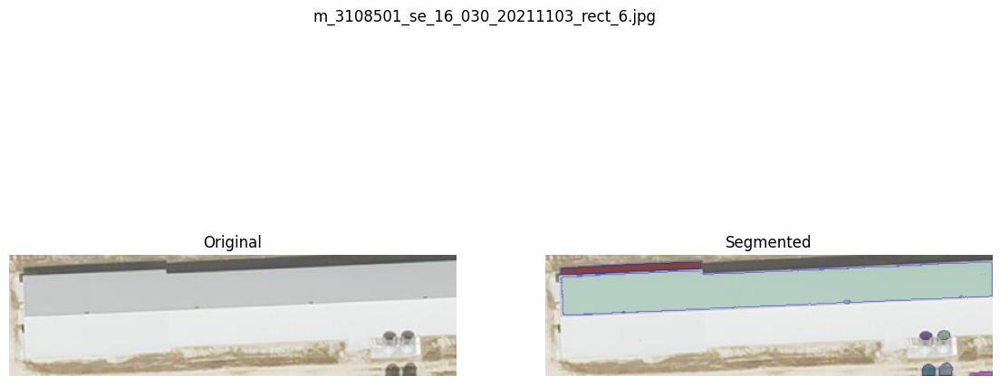

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_7_sam2.png


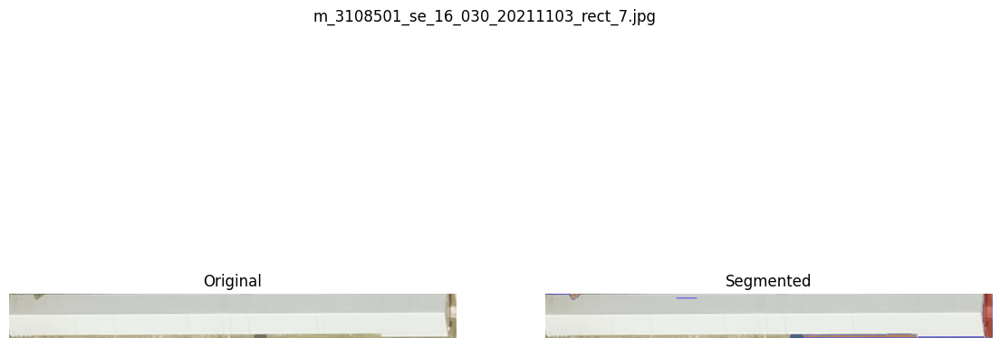

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_8_sam2.png


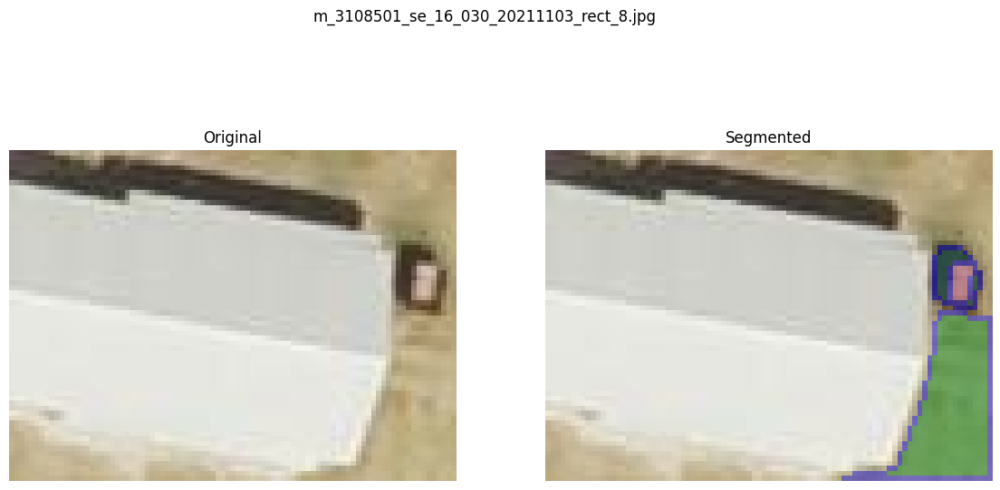

Saved: sam2_output_vis/m_3108501_se_16_030_20211103_rect_9_sam2.png


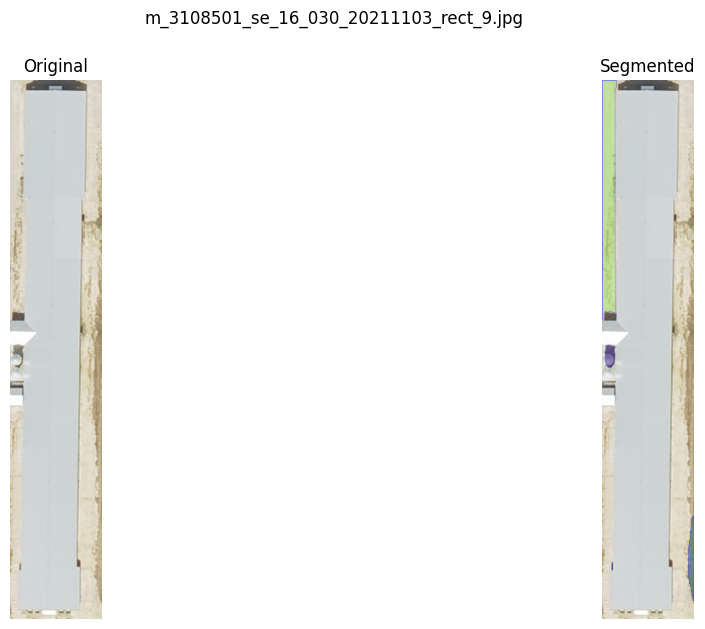

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_0_sam2.png


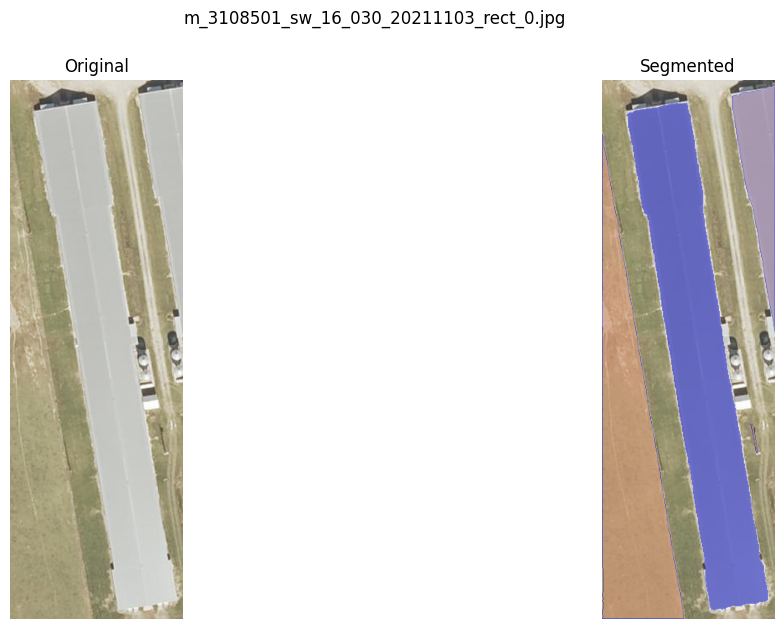

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_1_sam2.png


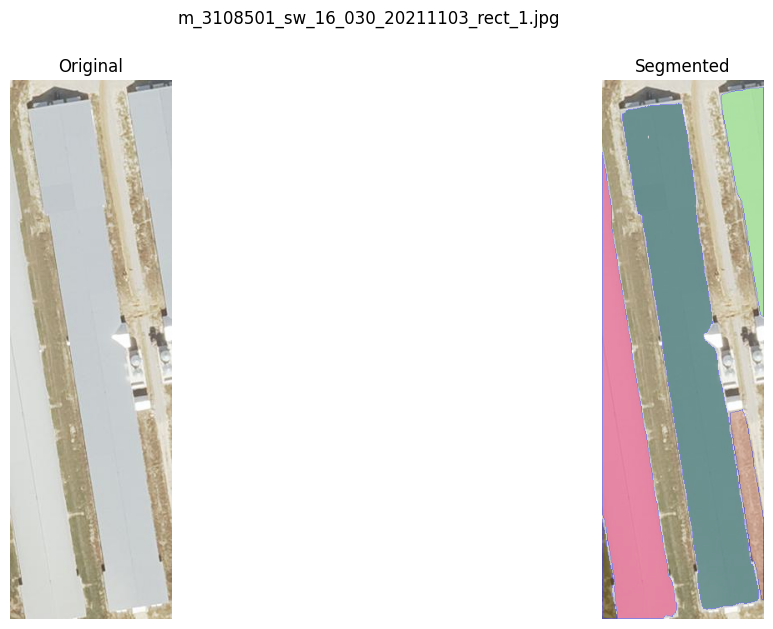

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_10_sam2.png


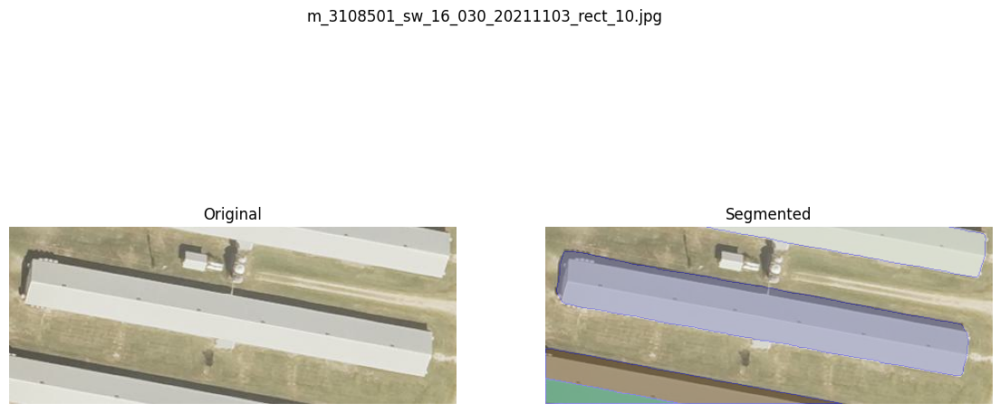

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_11_sam2.png


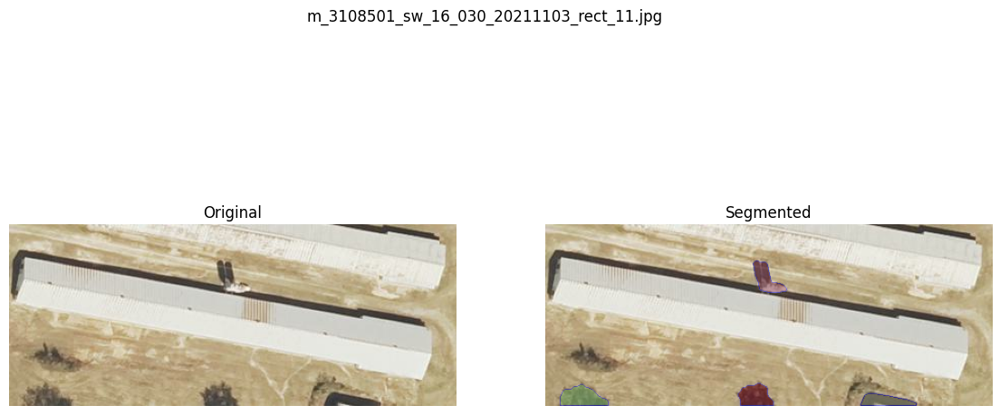

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_12_sam2.png


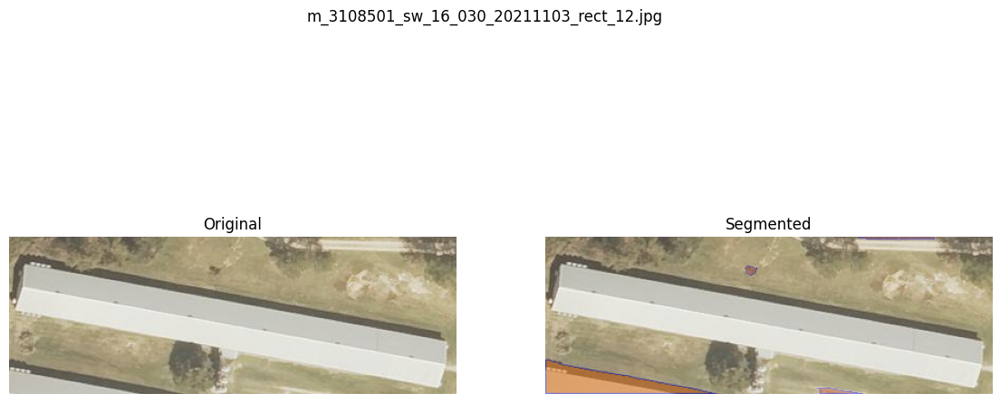

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_13_sam2.png


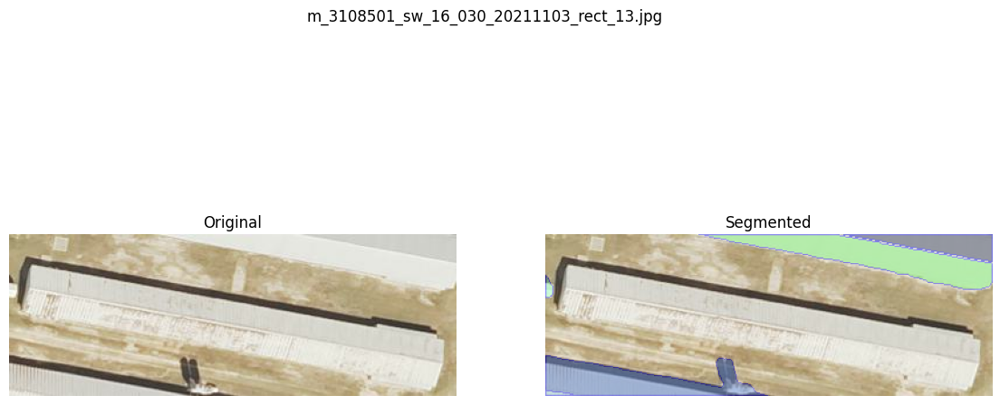

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_14_sam2.png


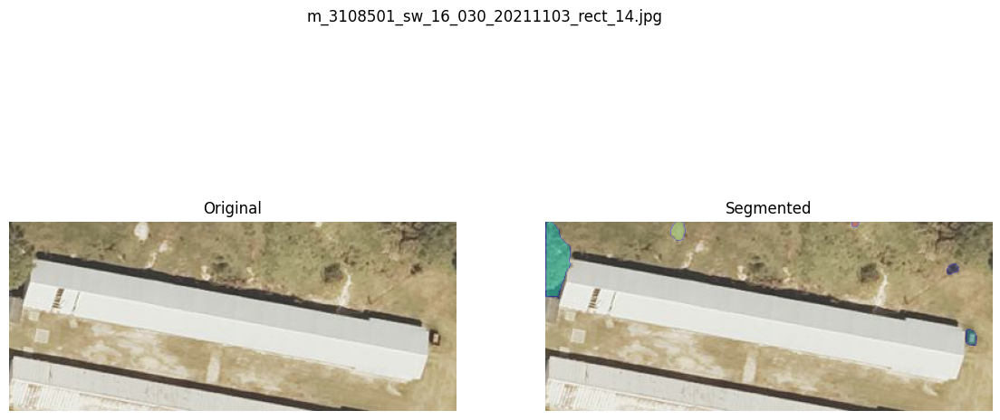

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_15_sam2.png


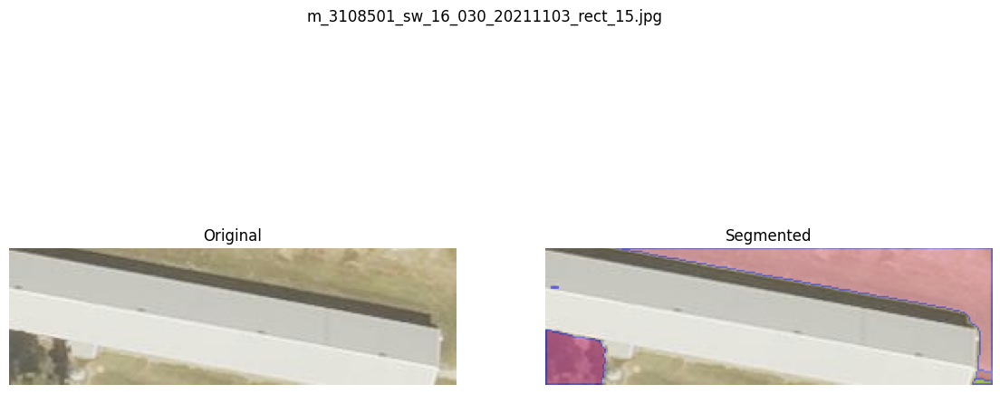

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_16_sam2.png


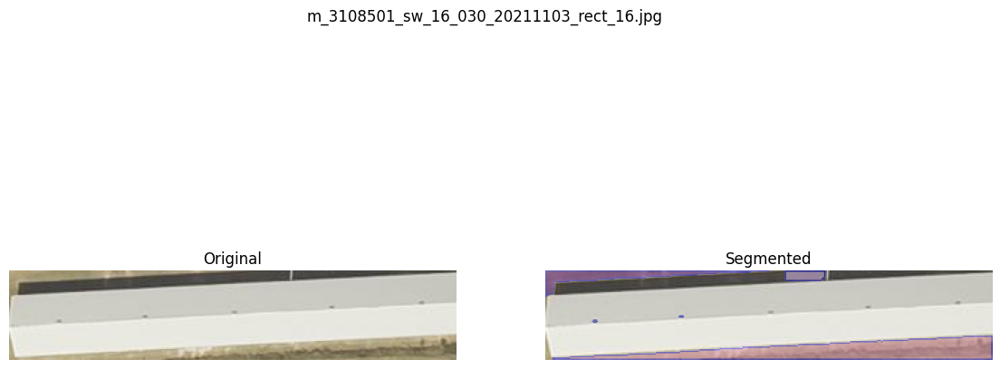

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_17_sam2.png


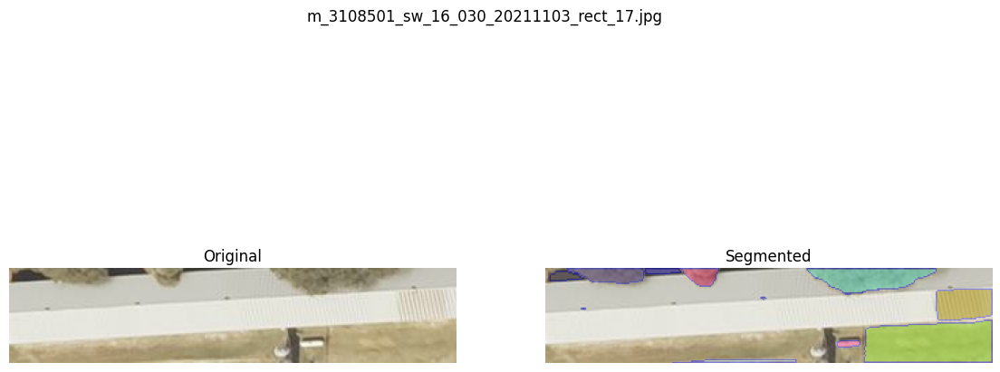

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_18_sam2.png


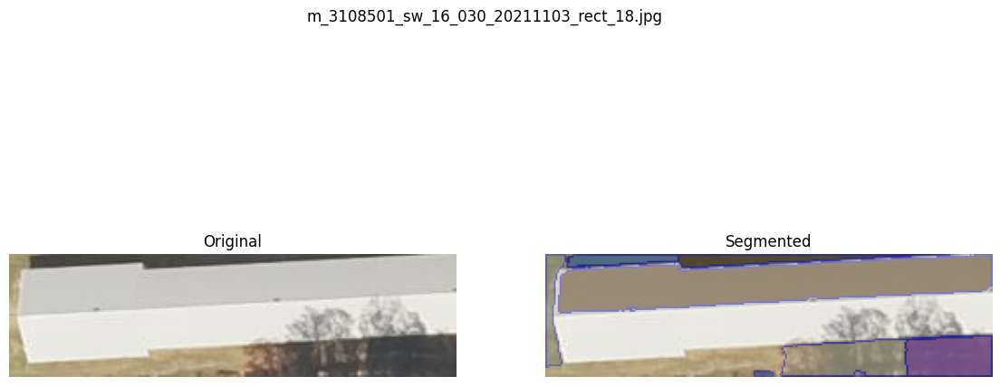

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_2_sam2.png


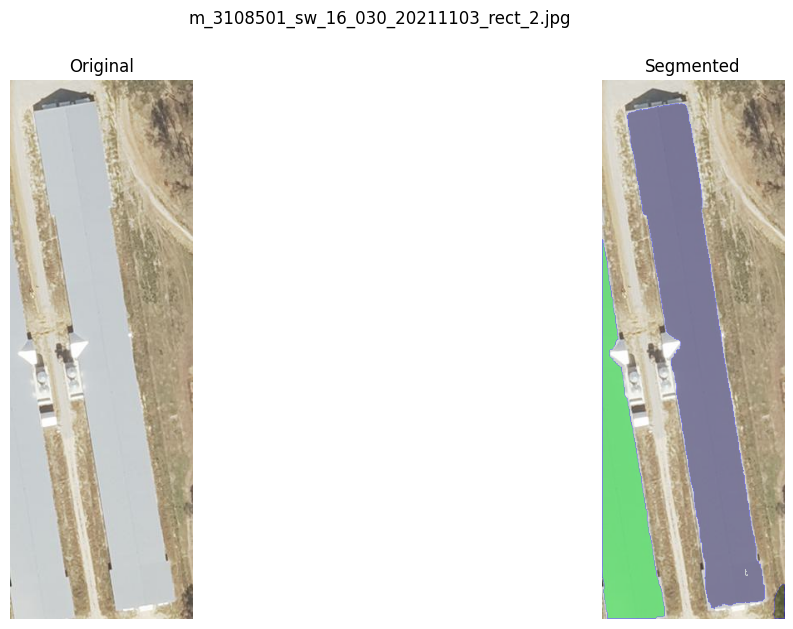

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_3_sam2.png


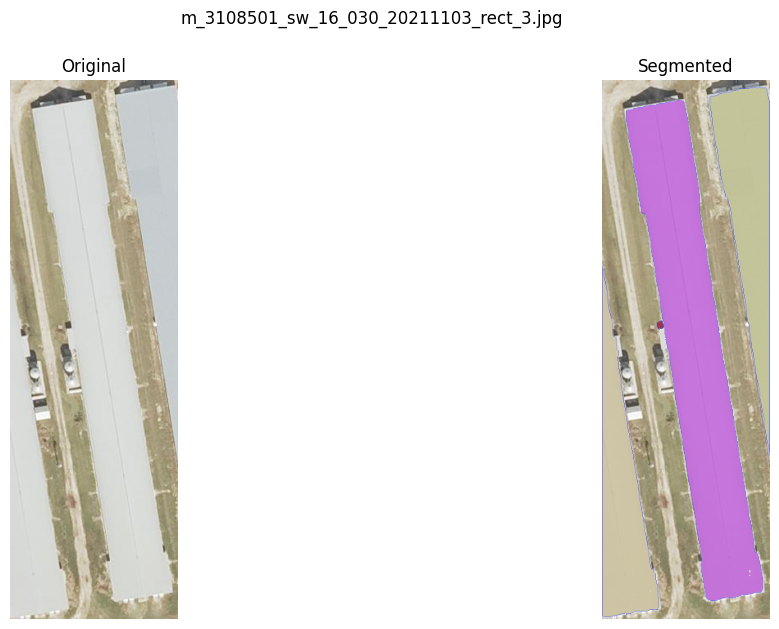

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_4_sam2.png


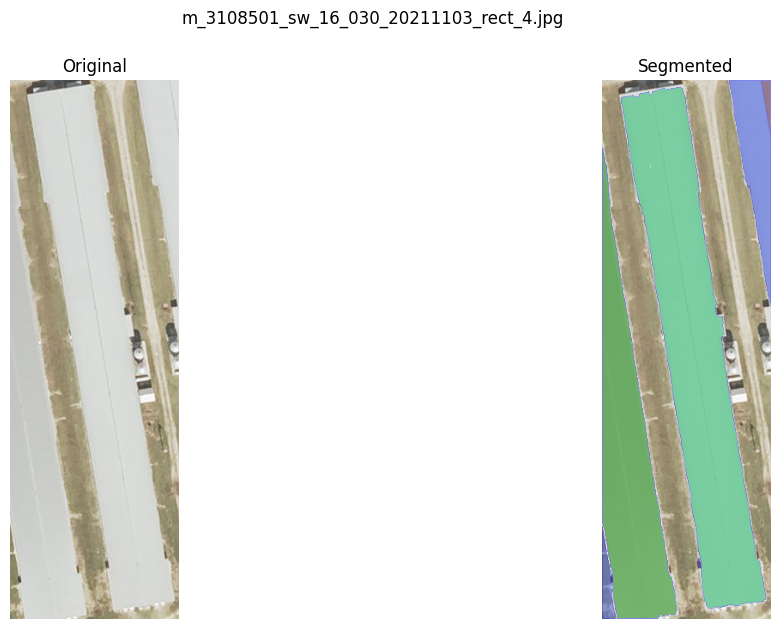

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_5_sam2.png


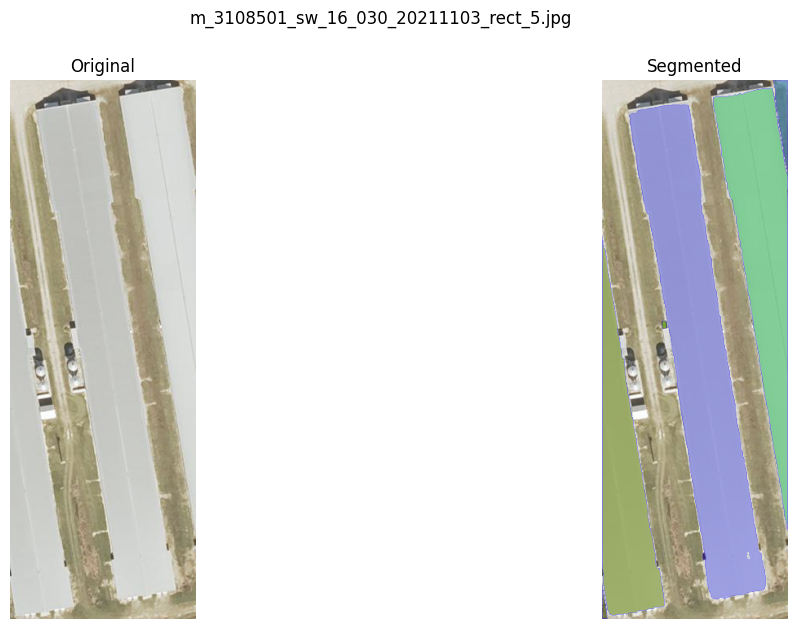

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_6_sam2.png


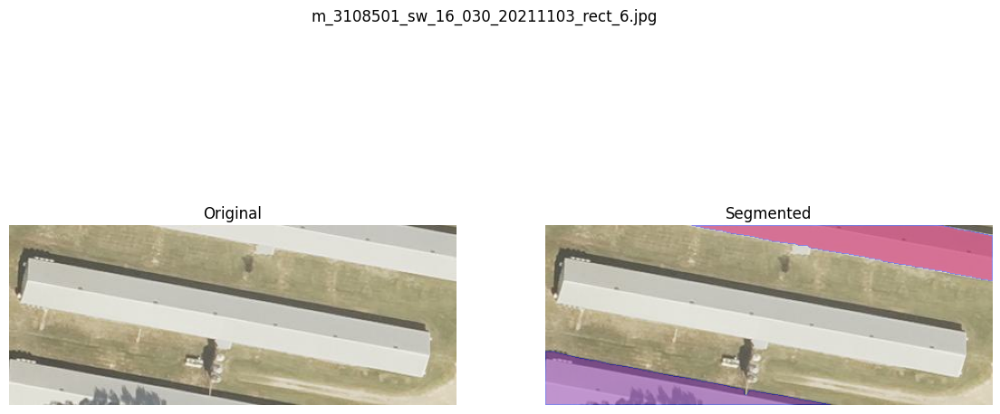

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_7_sam2.png


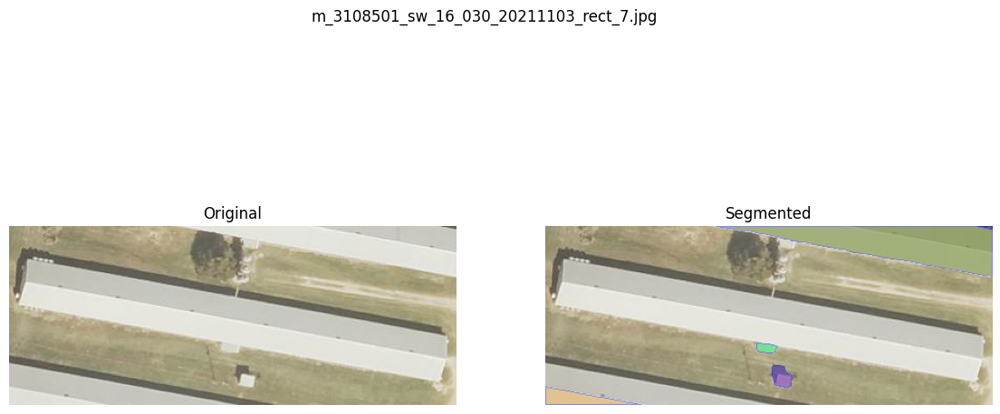

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_8_sam2.png


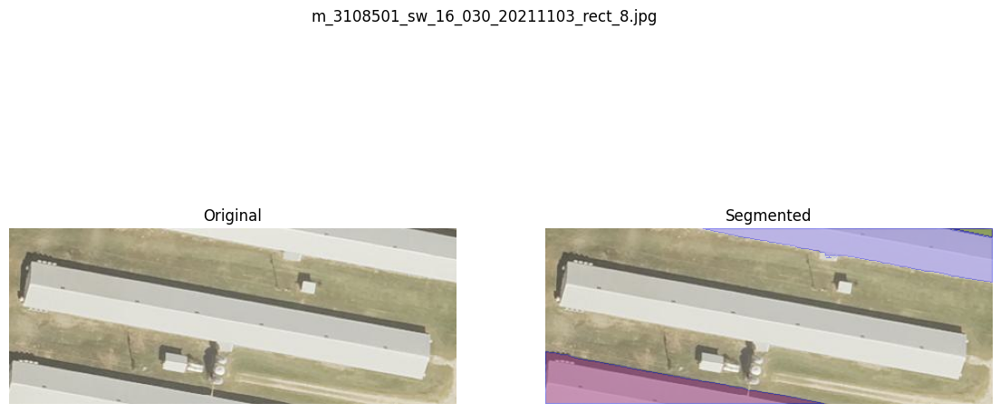

Saved: sam2_output_vis/m_3108501_sw_16_030_20211103_rect_9_sam2.png


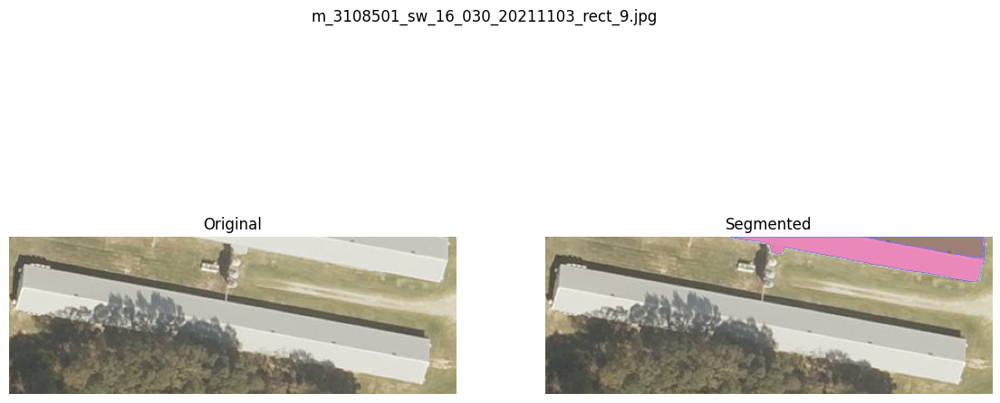

Saved: sam2_output_vis/m_3108502_ne_16_030_20211103_rect_0_sam2.png


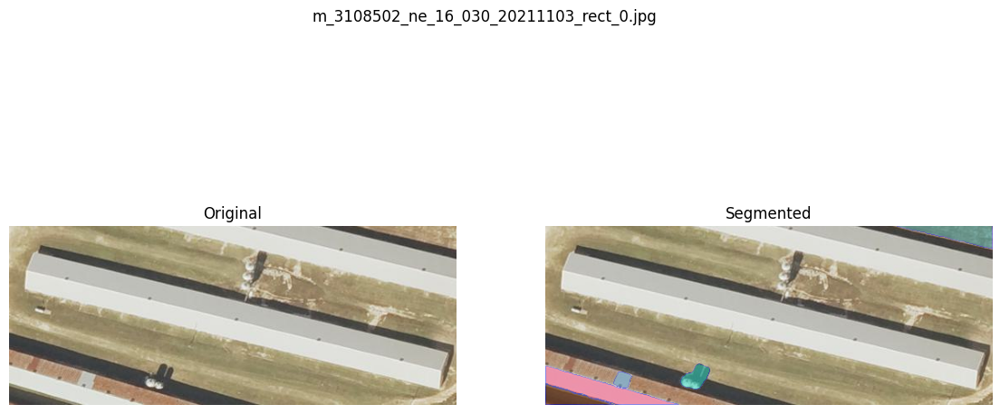

Saved: sam2_output_vis/m_3108502_ne_16_030_20211103_rect_1_sam2.png


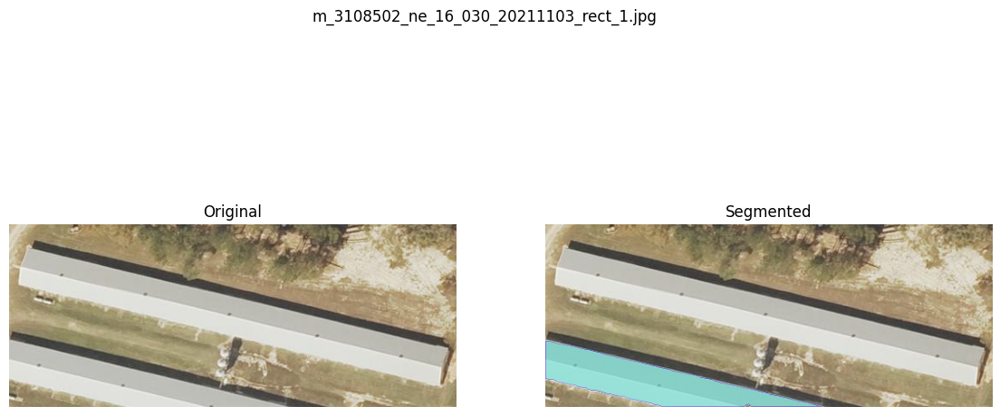

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_0_sam2.png


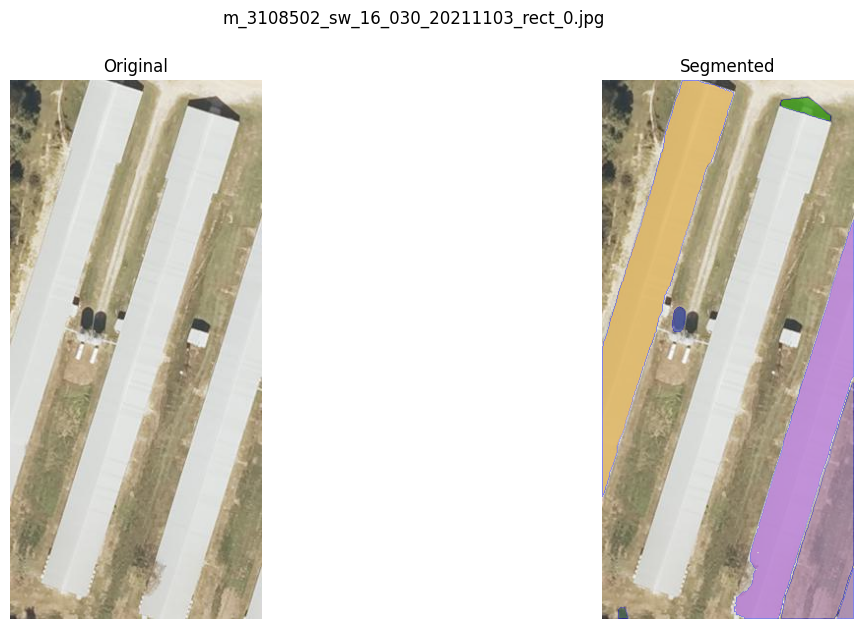

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_1_sam2.png


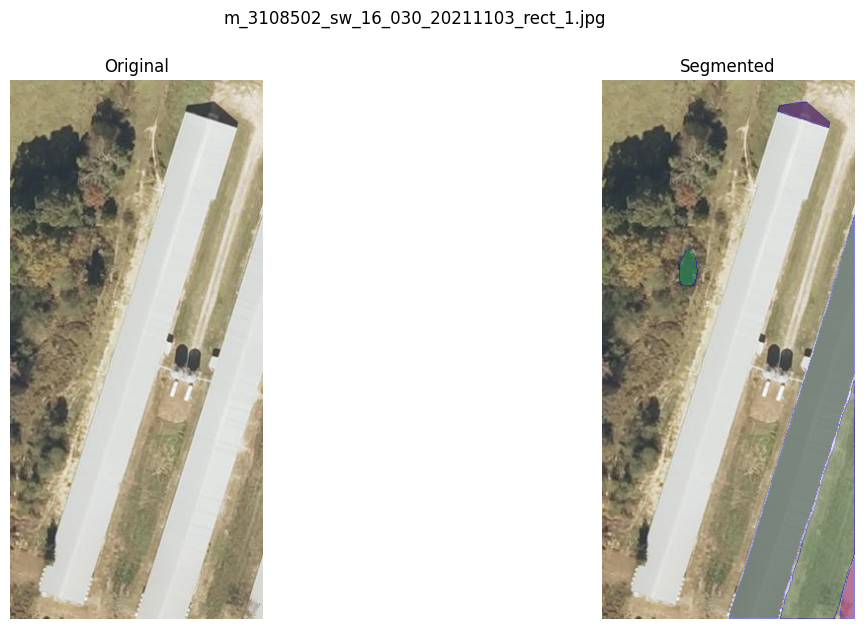

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_10_sam2.png


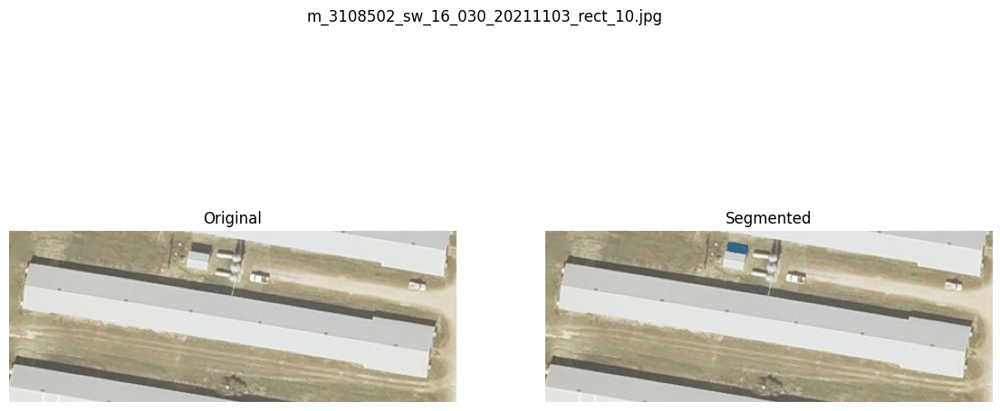

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_11_sam2.png


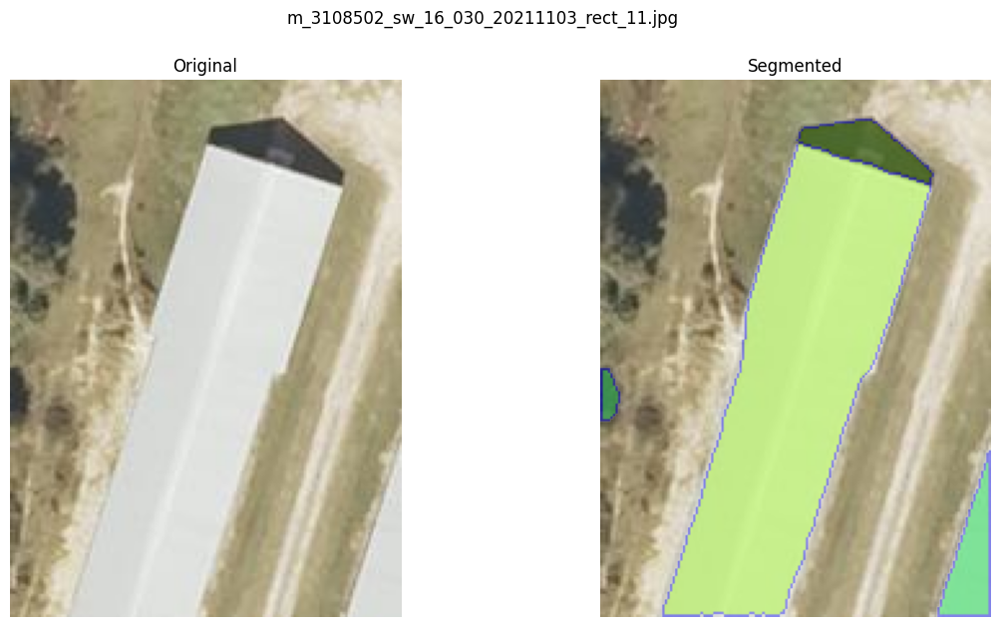

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_12_sam2.png


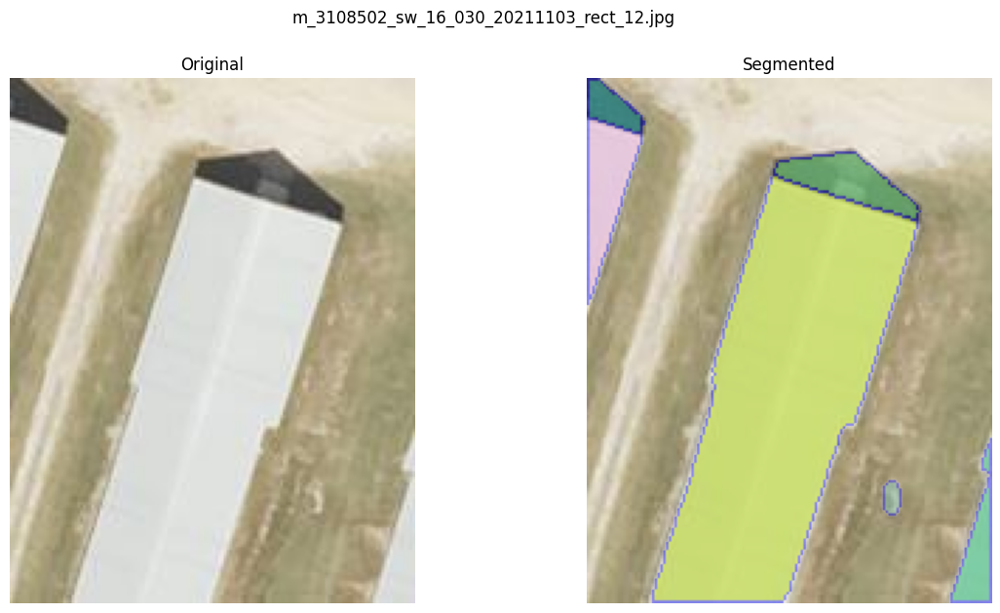

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_13_sam2.png


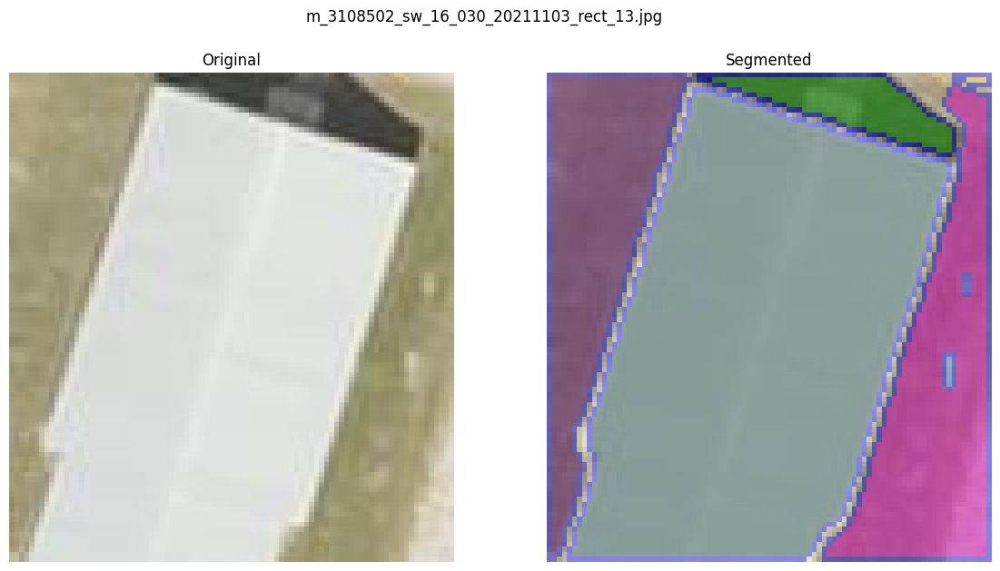

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_14_sam2.png


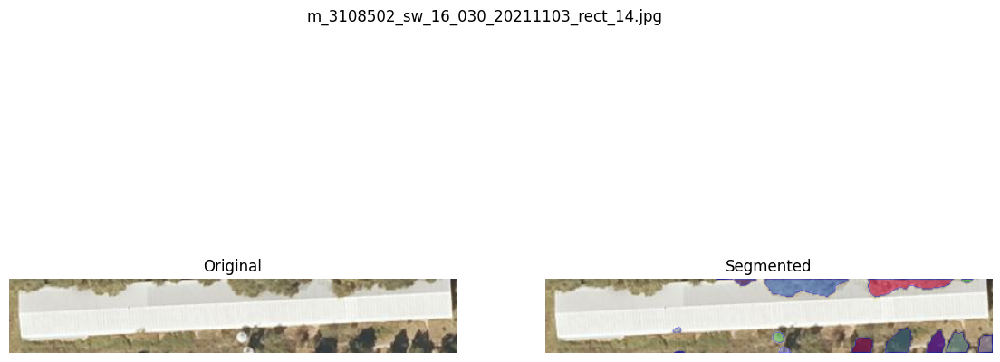

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_15_sam2.png


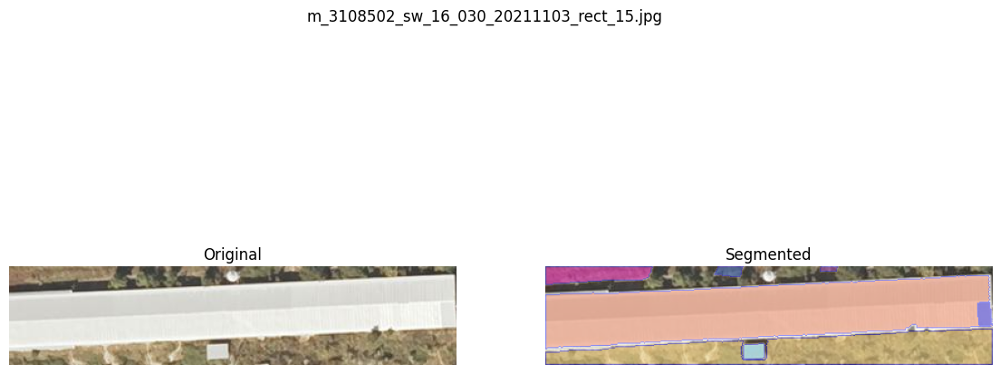

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_16_sam2.png


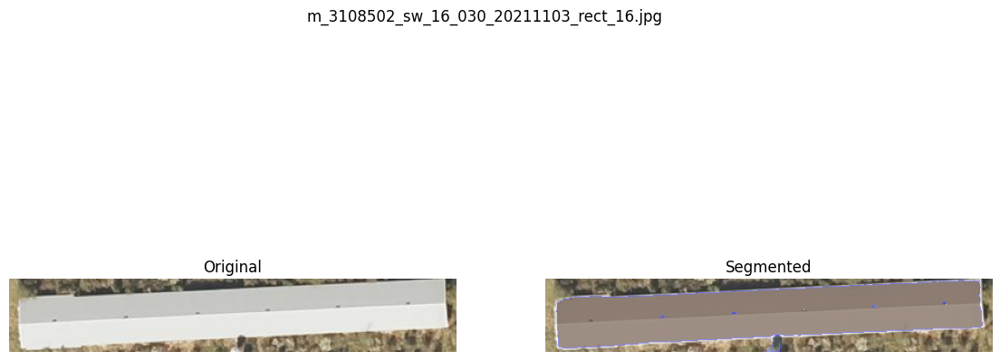

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_17_sam2.png


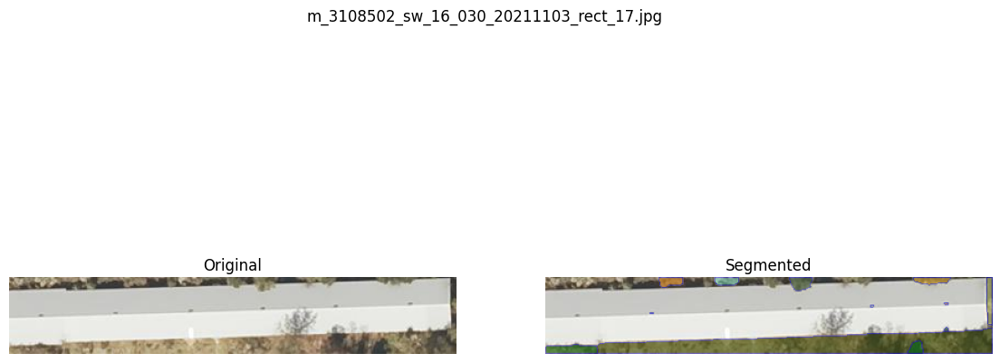

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_18_sam2.png


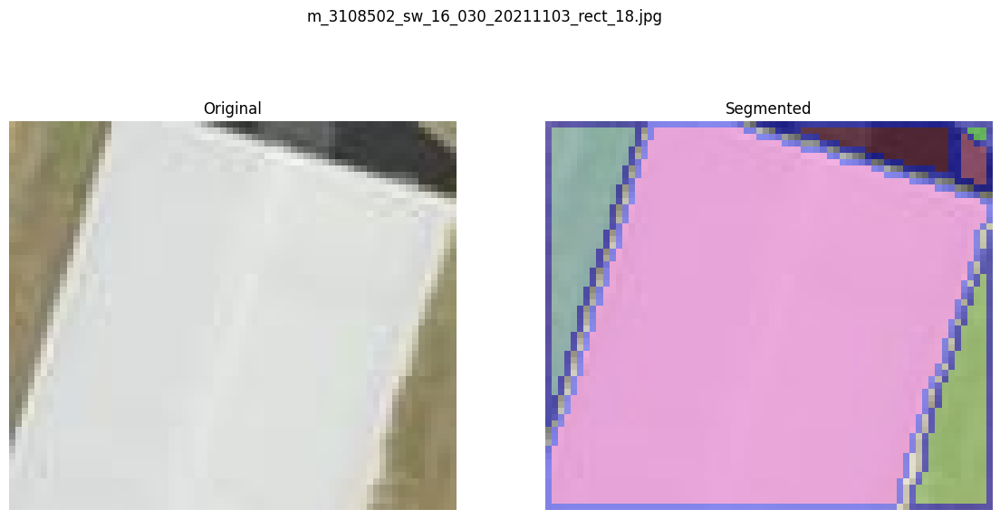

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_2_sam2.png


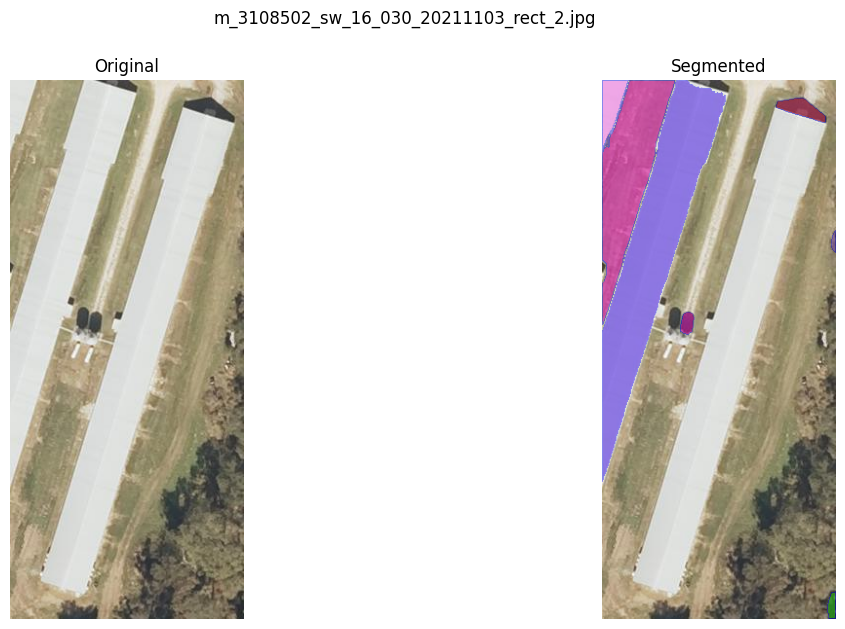

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_3_sam2.png


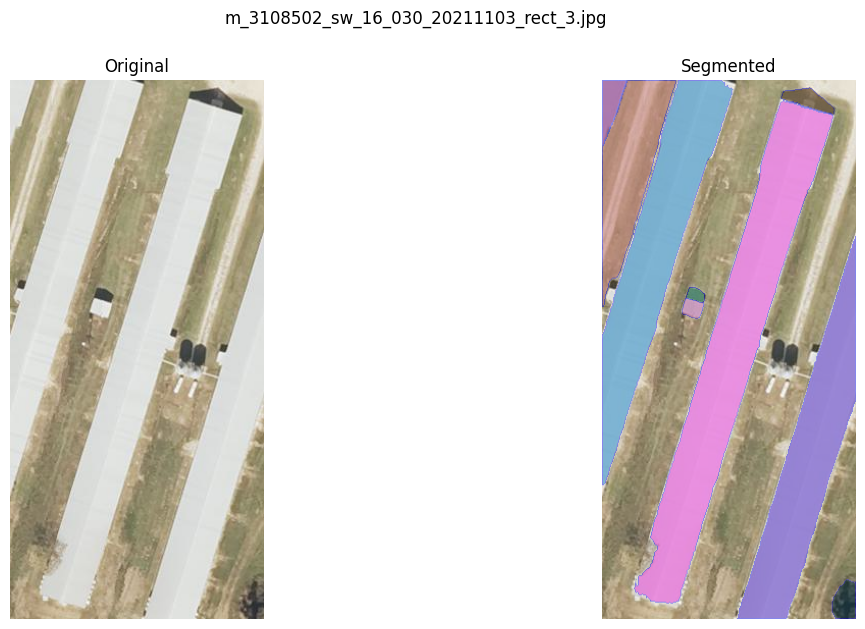

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_4_sam2.png


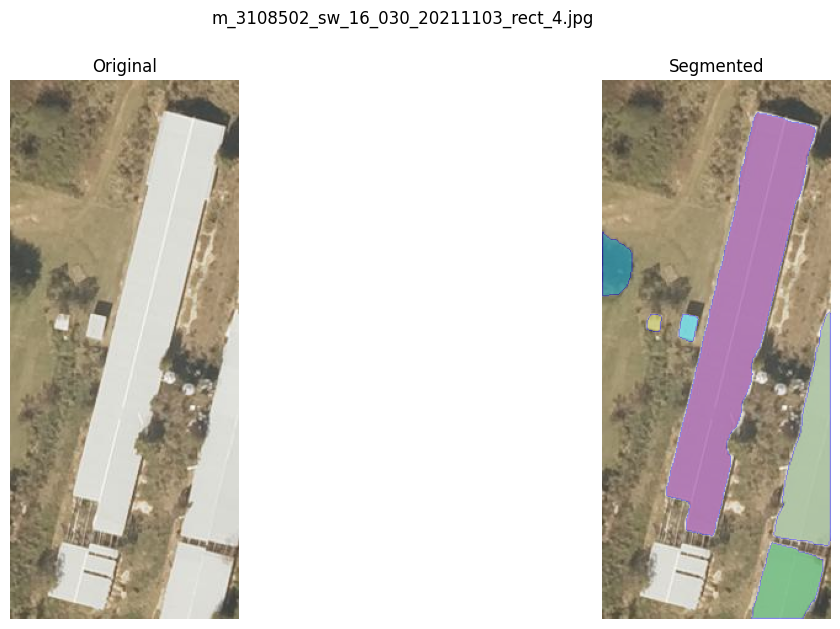

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_5_sam2.png


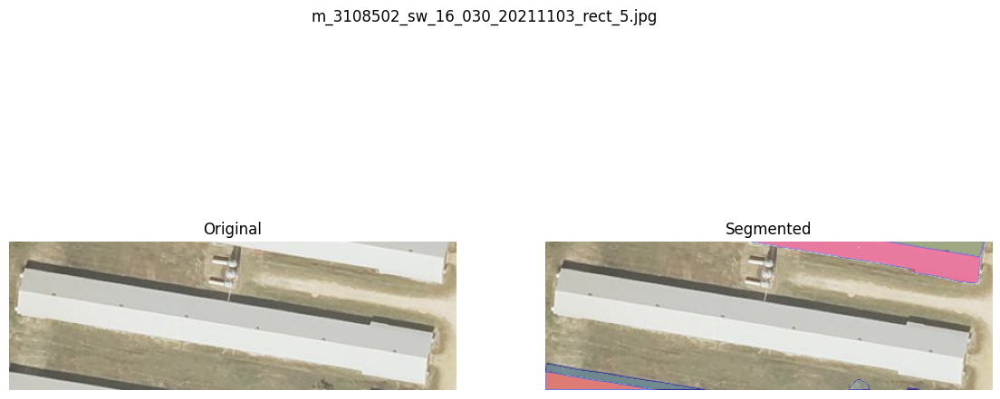

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_6_sam2.png


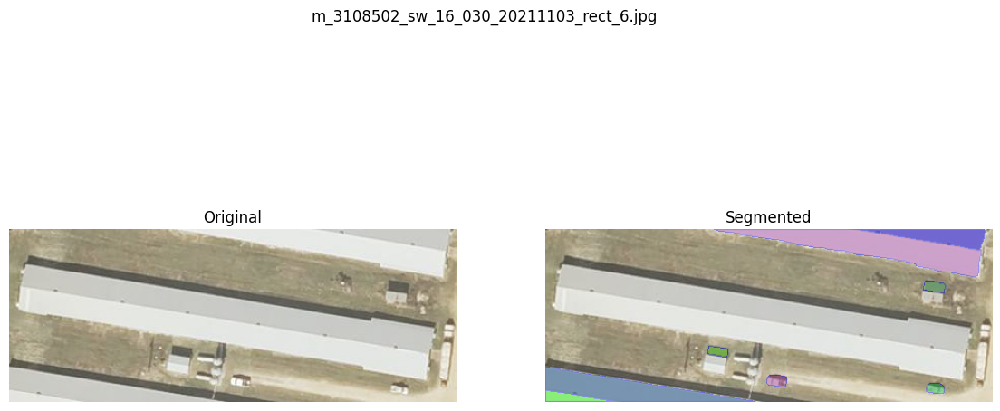

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_7_sam2.png


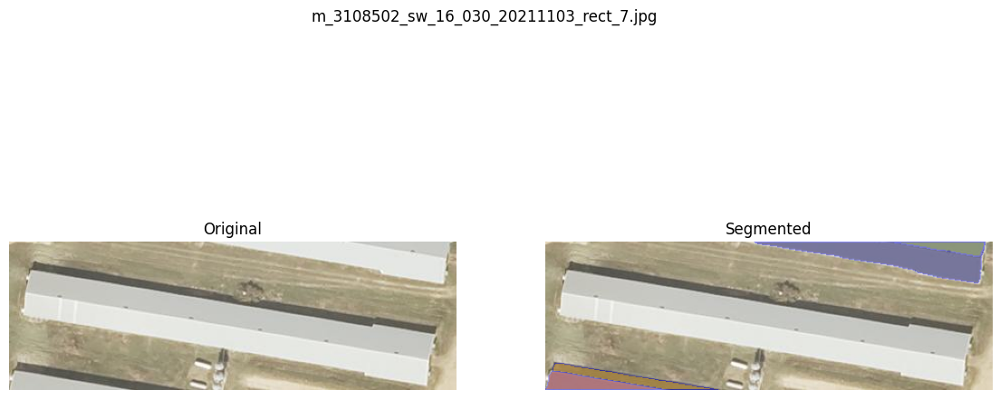

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_8_sam2.png


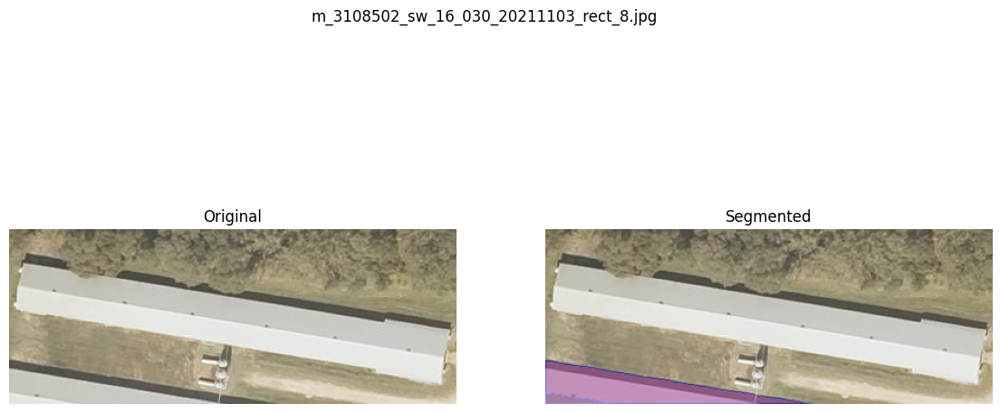

Saved: sam2_output_vis/m_3108502_sw_16_030_20211103_rect_9_sam2.png


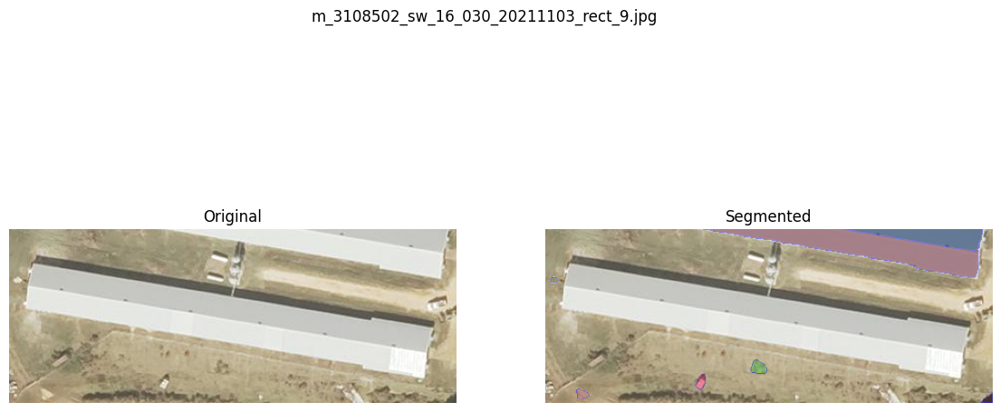

Saved: sam2_output_vis/m_3108503_ne_16_030_20211114_rect_0_sam2.png


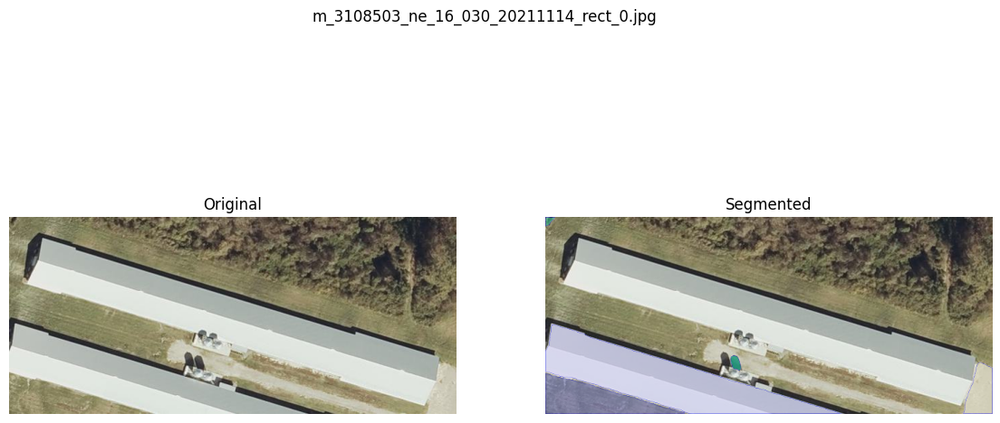

Saved: sam2_output_vis/m_3108503_ne_16_030_20211114_rect_1_sam2.png


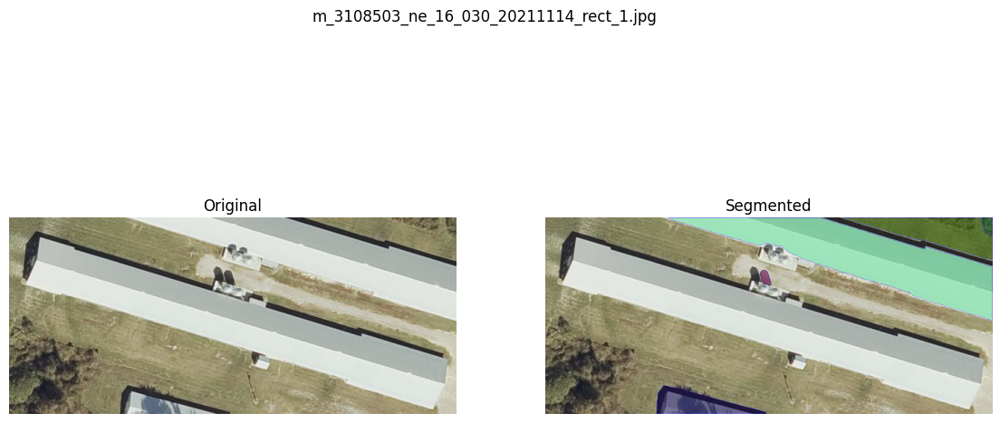

Saved: sam2_output_vis/m_3108503_ne_16_030_20211114_rect_2_sam2.png


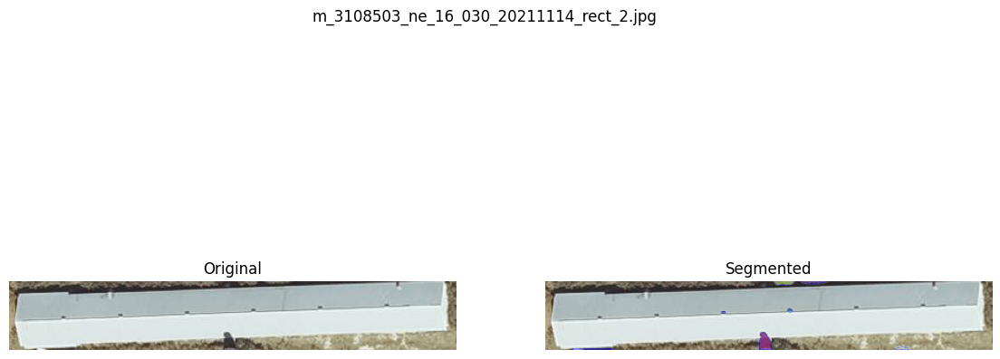

Saved: sam2_output_vis/m_3108503_ne_16_030_20211114_rect_3_sam2.png


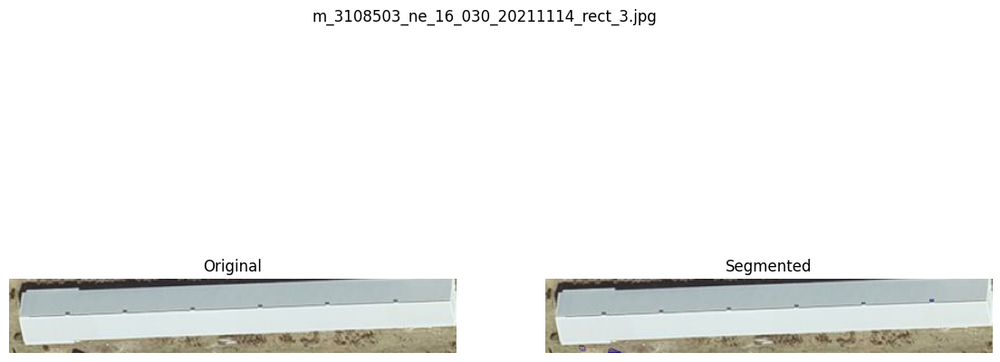

Saved: sam2_output_vis/m_3108503_ne_16_030_20211114_rect_4_sam2.png


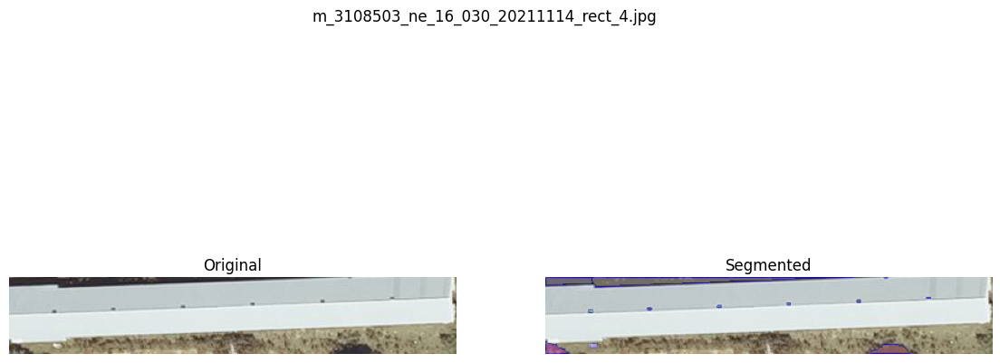

Saved: sam2_output_vis/m_3108503_se_16_030_20211103_rect_0_sam2.png


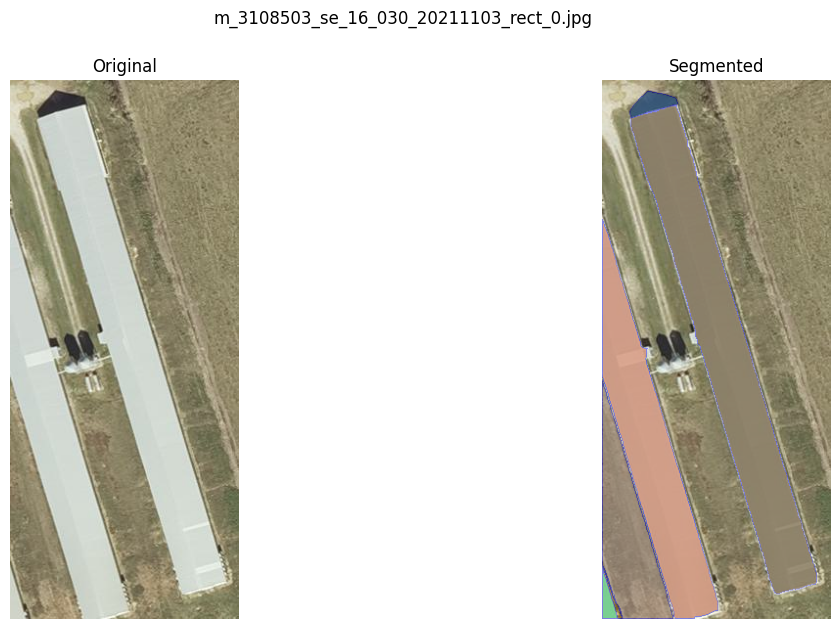

Saved: sam2_output_vis/m_3108503_se_16_030_20211103_rect_1_sam2.png


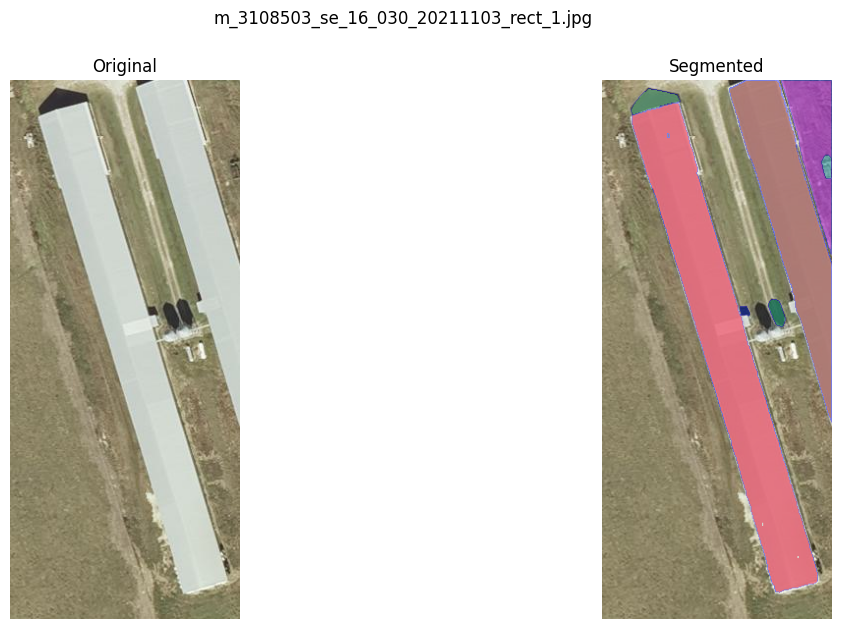

Saved: sam2_output_vis/m_3108503_se_16_030_20211103_rect_2_sam2.png


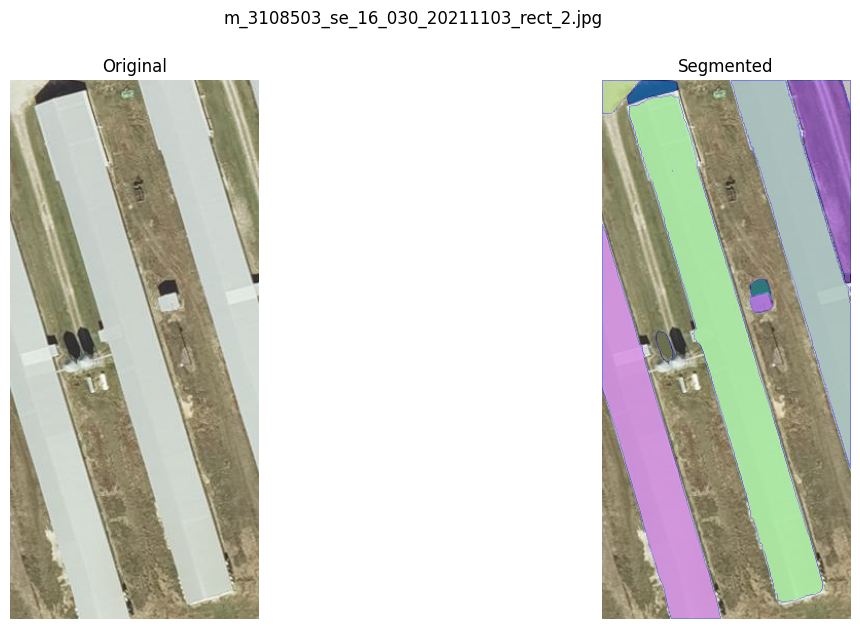

Saved: sam2_output_vis/m_3108503_se_16_030_20211103_rect_3_sam2.png


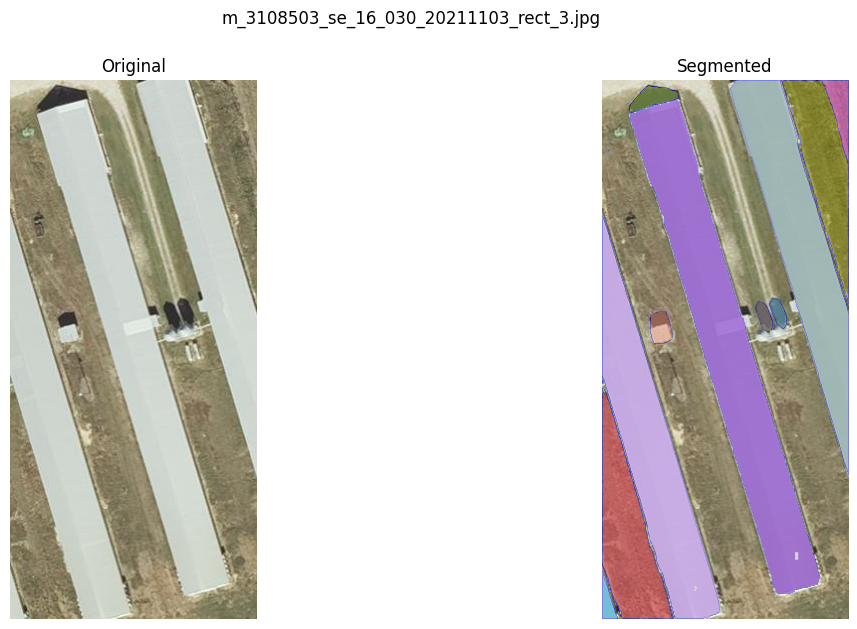

Saved: sam2_output_vis/m_3108503_sw_16_030_20211103_rect_0_sam2.png


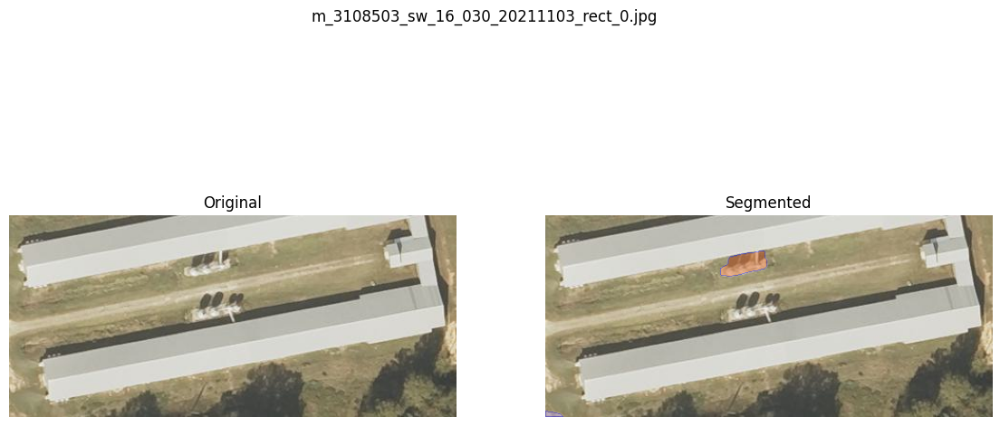

Saved: sam2_output_vis/m_3108503_sw_16_030_20211103_rect_1_sam2.png


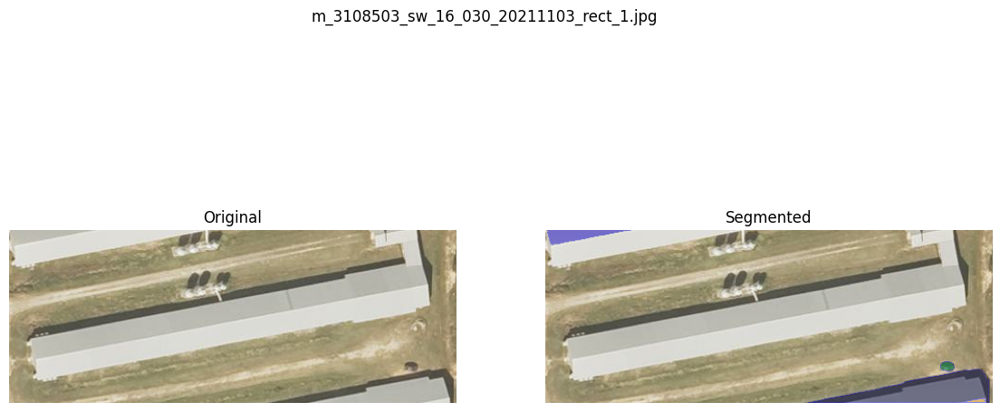

Saved: sam2_output_vis/m_3108503_sw_16_030_20211103_rect_2_sam2.png


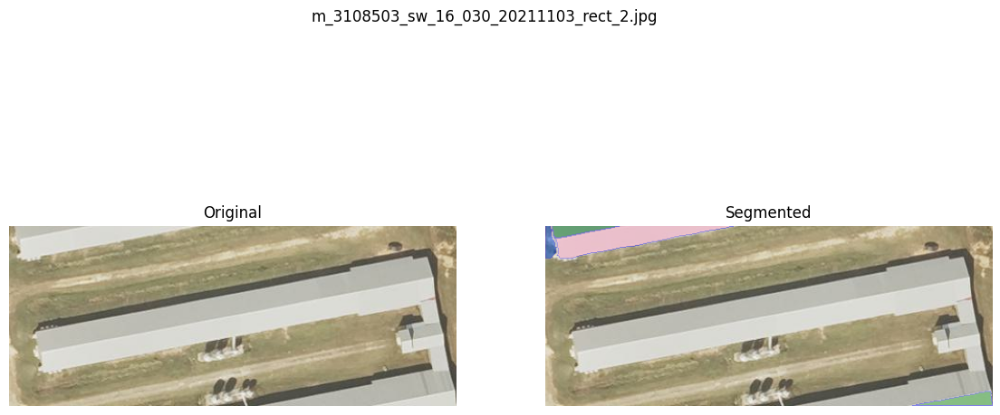

Saved: sam2_output_vis/m_3108503_sw_16_030_20211103_rect_3_sam2.png


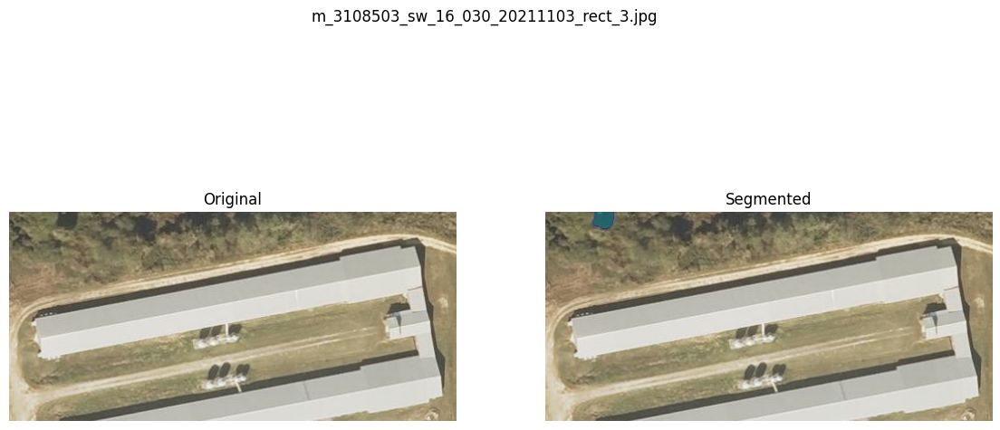

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_0_sam2.png


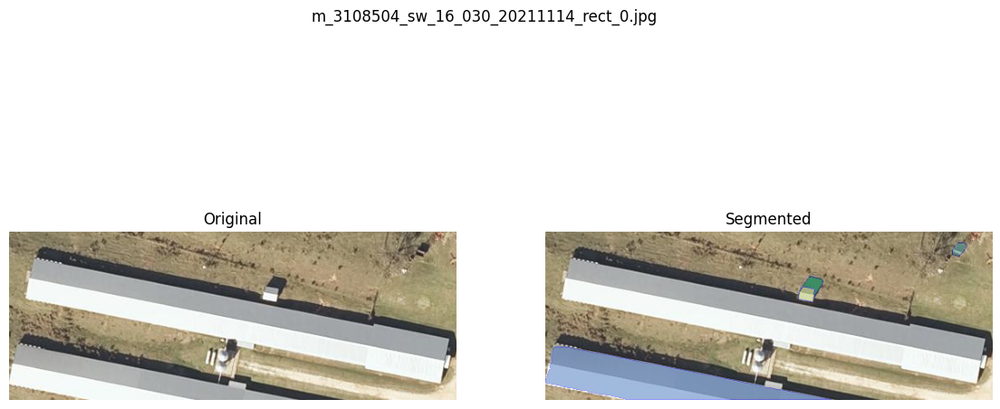

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_1_sam2.png


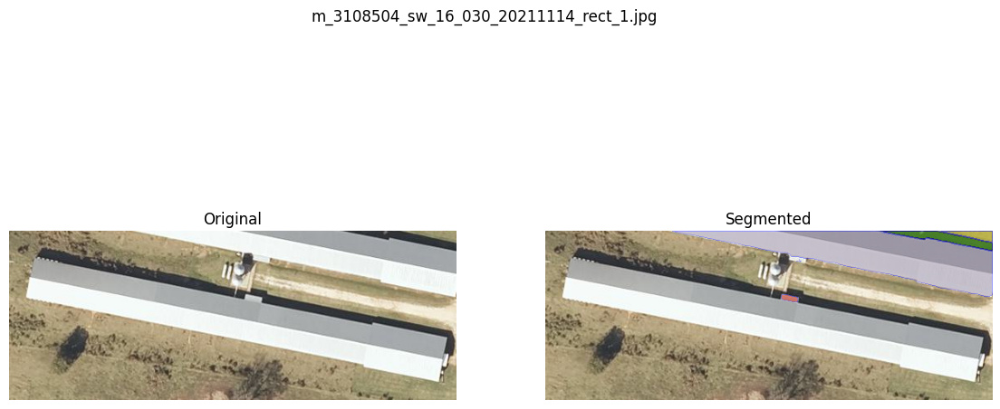

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_10_sam2.png


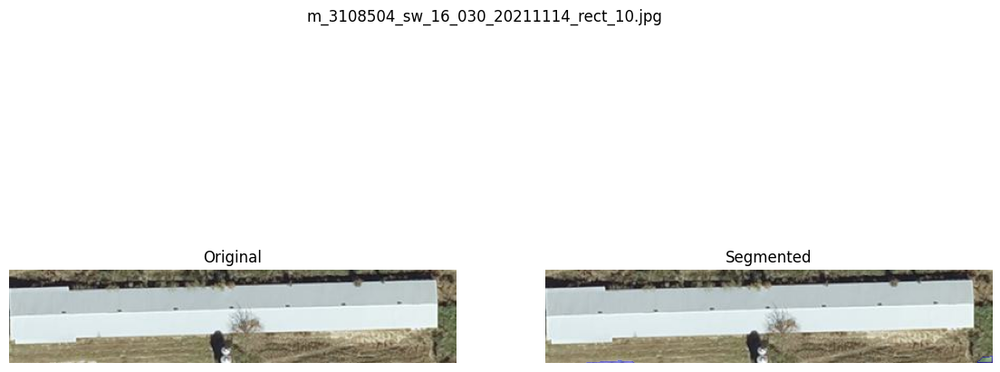

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_11_sam2.png


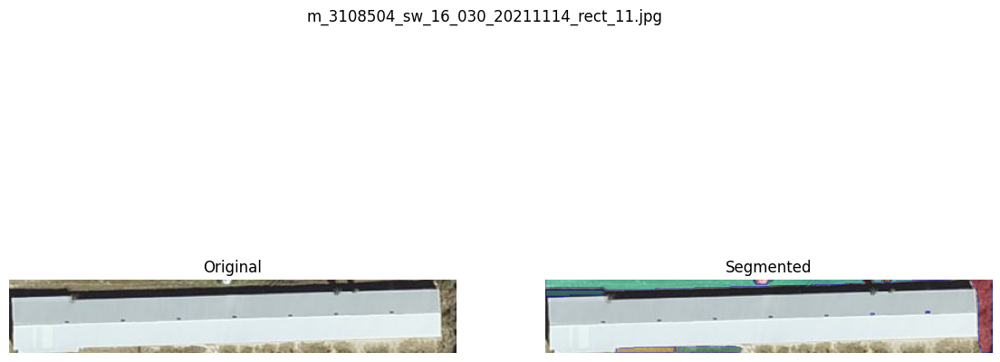

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_12_sam2.png


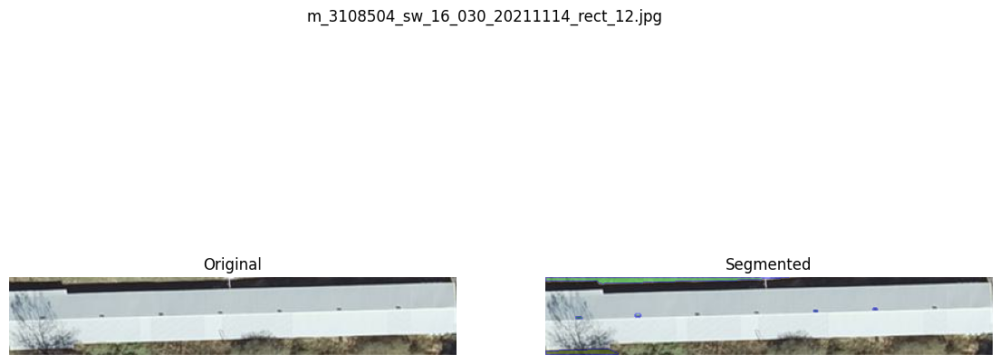

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_13_sam2.png


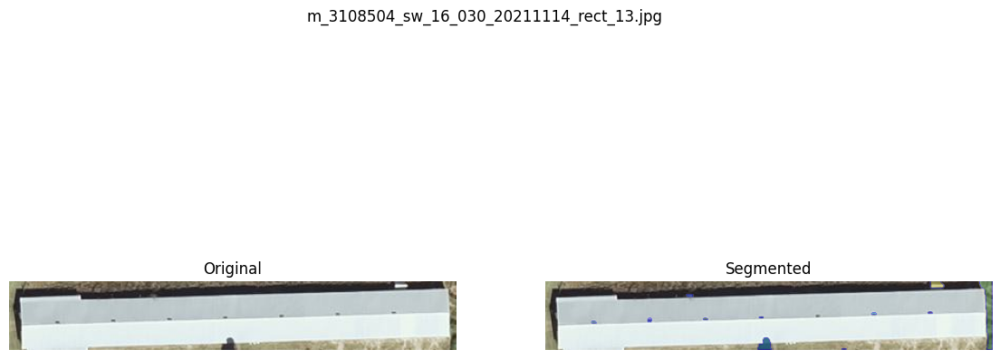

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_2_sam2.png


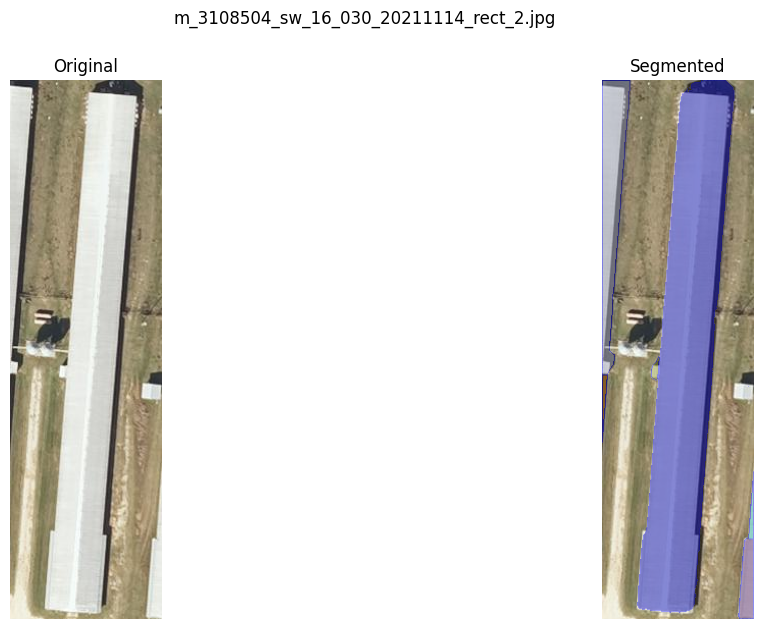

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_3_sam2.png


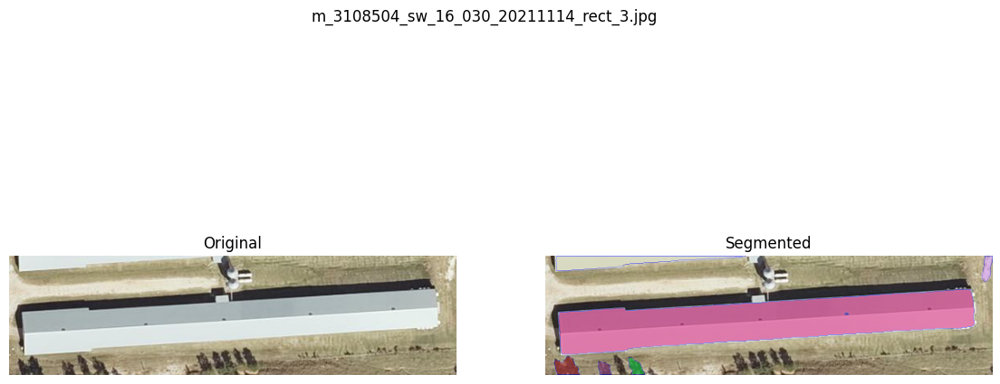

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_4_sam2.png


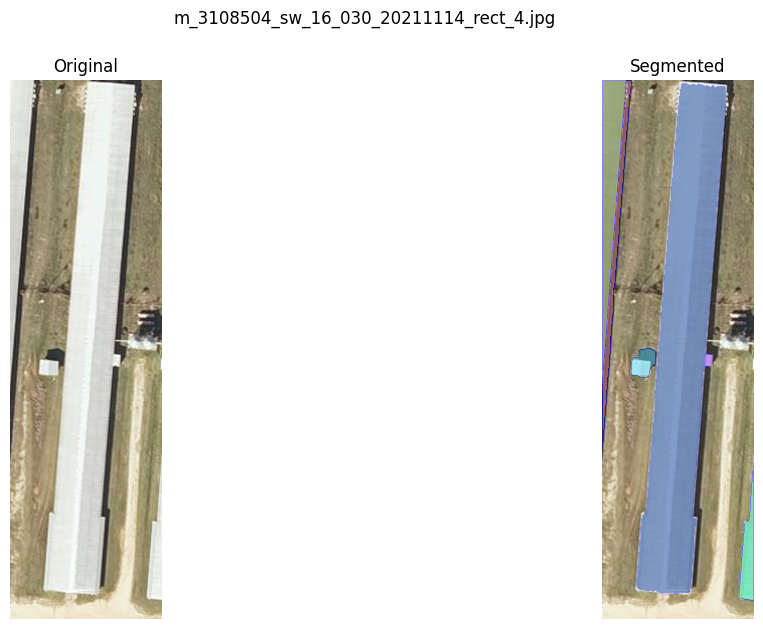

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_5_sam2.png


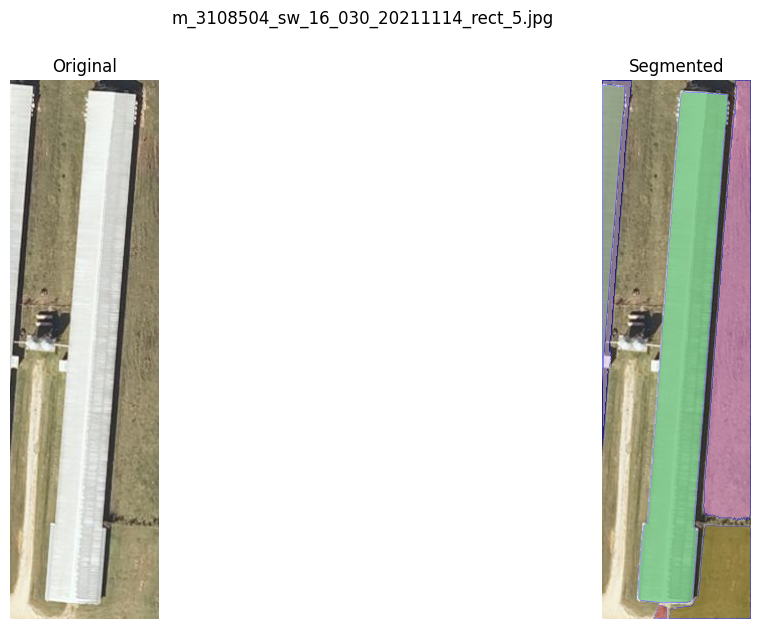

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_6_sam2.png


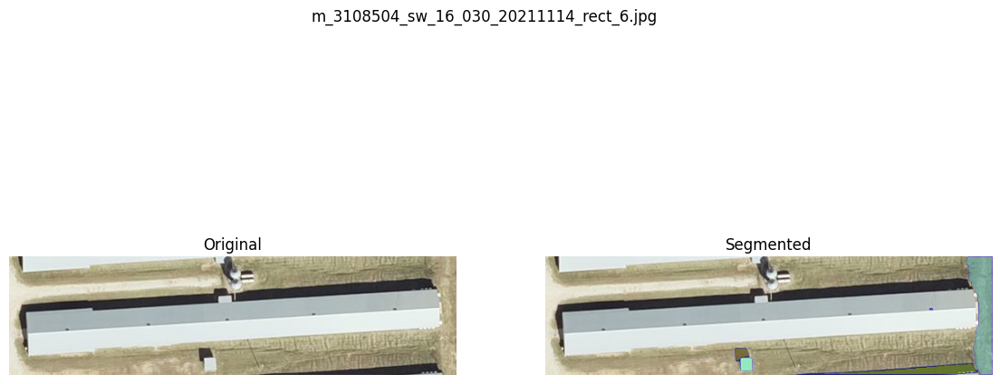

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_7_sam2.png


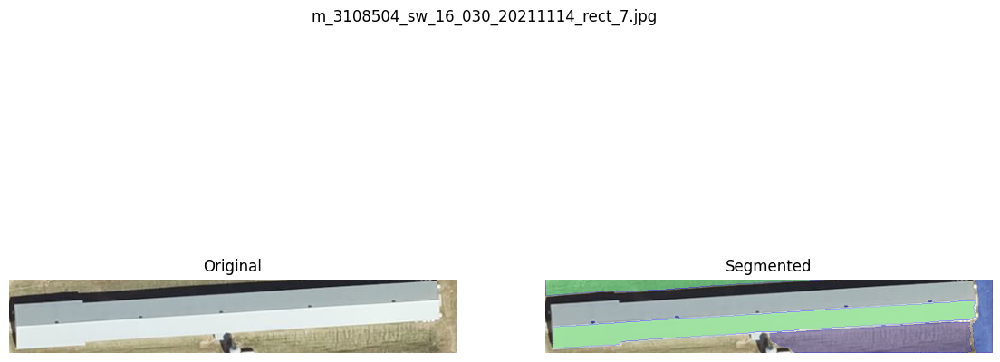

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_8_sam2.png


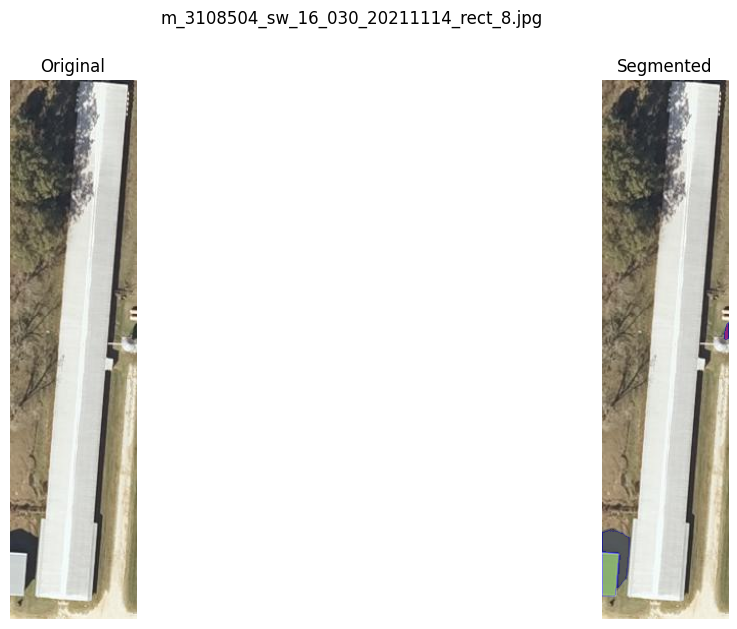

Saved: sam2_output_vis/m_3108504_sw_16_030_20211114_rect_9_sam2.png


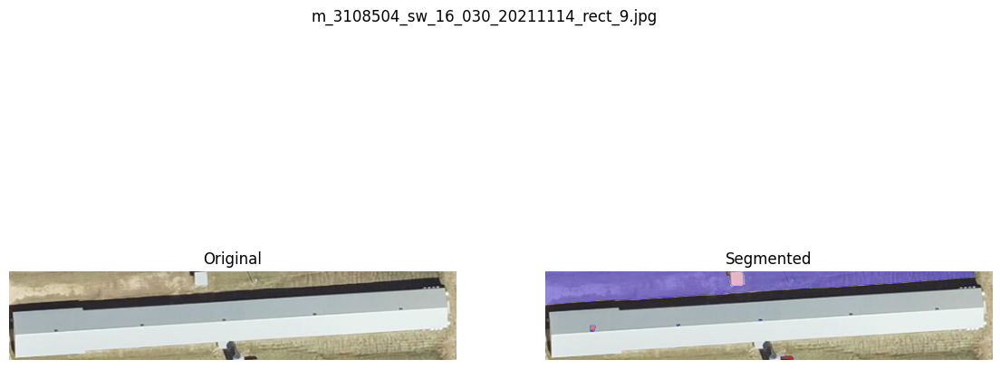

In [2]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sam2.build_sam import build_sam2
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator
import glob

# Set device (your existing logic)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"using device: {device}")

if device.type == "cuda":
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
elif device.type == "mps":
    print(
        "\nSupport for MPS devices is preliminary. SAM 2 is trained with CUDA and might "
        "give numerically different outputs and sometimes degraded performance on MPS."
    )

def show_anns(anns, borders=True):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=lambda x: x['area'], reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:, :, 3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.5]])
        img[m] = color_mask
        if borders:
            import cv2
            contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
            contours = [cv2.approxPolyDP(contour, epsilon=0.01, closed=True) for contour in contours]
            cv2.drawContours(img, contours, -1, (0, 0, 1, 0.4), thickness=1)
    ax.imshow(img)

# Initialize SAM2 and mask generator
sam2_checkpoint = "../checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"
sam2 = build_sam2(model_cfg, sam2_checkpoint, device=device, apply_postprocessing=False)
mask_generator = SAM2AutomaticMaskGenerator(sam2)

# mask_generator = SAM2AutomaticMaskGenerator(
#     model=sam2,
#     points_per_side=32,
#     points_per_batch=128,
#     pred_iou_thresh=0.7,
#     stability_score_thresh=0.92,
#     stability_score_offset=0.7,
#     crop_n_layers=1,
#     box_nms_thresh=0.7,
#     crop_n_points_downscale_factor=2,
#     min_mask_region_area=25.0,
#     use_m2m=True,
# )

# Batch process
def batch_sam2_visualize(image_dir, output_dir=None, save_images=False):
    os.makedirs(output_dir, exist_ok=True) if save_images and output_dir else None
    image_paths = sorted(glob.glob(os.path.join(image_dir, "*")))
    print(f"Found {len(image_paths)} images.")

    for img_path in image_paths:
        try:
            image = Image.open(img_path).convert("RGB")
            image_np = np.array(image)
            masks = mask_generator.generate(image_np)

            plt.figure(figsize=(14, 7))
            plt.subplot(1, 2, 1)
            plt.imshow(image_np)
            plt.title("Original")
            plt.axis('off')
            plt.subplot(1, 2, 2)
            plt.imshow(image_np)
            show_anns(masks)
            plt.title("Segmented")
            plt.axis('off')
            plt.suptitle(os.path.basename(img_path))

            if save_images and output_dir:
                out_name = os.path.splitext(os.path.basename(img_path))[0] + "_sam2.png"
                out_path = os.path.join(output_dir, out_name)
                plt.savefig(out_path, bbox_inches='tight')
                print(f"Saved: {out_path}")

            plt.show()
        except Exception as e:
            print(f"Error processing {img_path}: {e}")

# Example usage
batch_sam2_visualize(
    image_dir="cropped_rects/",      # Your image directory
    output_dir="sam2_output_vis",         # Optional output directory to save figures
    save_images=True                      # Set to True if you want to save figures
)
